# Space Debris Conjunction Risk Engine
End-to-end pipeline: TLE ingestion → propagation → ML screening → Physics Kalman → Neural Network → Conjunction Probability → Combined Risk Output

In [ ]:
!pip install skyfield imbalanced-learn xgboost torch scipy scikit-learn pandas numpy matplotlib -q
print("Dependencies ready")

Dependencies ready


## Part 1 — Load Satellite Catalog

In [ ]:
import random
import numpy as np
import pandas as pd
from skyfield.api import load

s_types = ['starlink', 'oneweb', 'iridium-33-debris',
           'cosmos-2251-debris', 'fengyun-1c-debris', 'cosmos-1408-debris']
base = 'https://celestrak.org/NORAD/elements/gp.php'
earth_sats = []

for s in s_types:
    url = f'{base}?GROUP={s}&FORMAT=tle'
    try:
        sats = load.tle_file(url, filename=f'{s}.tle')
        limits = {'starlink': 1000, 'oneweb': 400,
                  'fengyun-1c-debris': 400, 'cosmos-2251-debris': 300}
        if s in limits:
            sats = random.sample(sats, min(len(sats), limits[s]))
        earth_sats.extend(sats)
    except Exception as e:
        print(f'Error loading {s}: {e}')

pd.DataFrame([{'name': s.name, 'norad_id': s.model.satnum}
              for s in earth_sats]).to_csv('satellites.csv', index=False)
print(f'Total satellites loaded: {len(earth_sats)}')

Total satellites loaded: 2214


## Part 2 — Vectorized SGP4 Propagation
Propagate every satellite across 144 timesteps (10-min intervals, 24h window). One SGP4 call per satellite — Skyfield vectorizes internally.

In [ ]:
ts = load.timescale()
day_offset = 16

# Define Canonical Forecast Start
forecast_start_time = ts.now() + day_offset
forecast_start_tt = forecast_start_time.tt

detail_minutes = np.arange(0, 1440, 10)
detail_times   = forecast_start_time + detail_minutes / 1440

# FIX 3: Finer screening cadence (1-min) to avoid temporal blind spots
filter_minutes = np.arange(0, 1440, 1)
filter_times   = forecast_start_time + filter_minutes / 1440

n_sats = len(earth_sats)
all_positions_detail = np.zeros((n_sats, len(detail_times), 3))
all_velocities_detail = np.zeros((n_sats, len(detail_times), 3))
all_altitudes_detail = np.zeros((n_sats, len(detail_times)))
all_positions_filter = np.zeros((n_sats, len(filter_times), 3))

print(f'Propagating {n_sats} sats. Forecast Start TT: {forecast_start_tt:.4f}')
# Diagnostic for sample sat
sample_sat = earth_sats[0]
print(f'DIAGNOSTIC [{sample_sat.name}]: Epoch: {sample_sat.epoch.tt:.4f} | Forecast Age: {forecast_start_tt - sample_sat.epoch.tt:.4f} days')

for i, sat in enumerate(earth_sats):
    geo_d = sat.at(detail_times)
    all_positions_detail[i] = geo_d.position.km.T
    all_velocities_detail[i] = geo_d.velocity.km_per_s.T
    all_altitudes_detail[i] = geo_d.subpoint().elevation.km
    all_positions_filter[i] = sat.at(filter_times).position.km.T

print('Propagation complete.')

Propagating 2214 sats. Forecast Start TT: 2461285.5685
DIAGNOSTIC [STARLINK-11376 [DTC]]: Epoch: 2461268.7641 | Forecast Age: 16.8044 days
Propagation complete.


In [ ]:
import numpy as np
from scipy.optimize import minimize_scalar

# TCA Refinement Diagnostic for Sample Sat
sample_sat = earth_sats[0]
forecast_start_tt = detail_times[0].tt

print(f"--- Canonical Forecast Audit ---")
print(f"Satellite: {sample_sat.name}")
print(f"TLE Epoch TT:    {sample_sat.epoch.tt:.4f}")
print(f"Current Time TT: {ts.now().tt:.4f}")
print(f"Forecast Start TT: {forecast_start_tt:.4f}")
print(f"Forecast Age (Days): {forecast_start_tt - sample_sat.epoch.tt:.4f}")

def get_high_res_separation(t_minutes, sat_a, sat_b, start_time):
    # Helper for scalar minimization
    t = start_time + t_minutes / 1440
    pos_a = sat_a.at(t).position.km
    pos_b = sat_b.at(t).position.km
    return np.linalg.norm(pos_a - pos_b)

print("\nHigh-resolution TCA refinement logic initialized.")

--- Canonical Forecast Audit ---
Satellite: STARLINK-11376 [DTC]
TLE Epoch TT:    2461268.7641
Current Time TT: 2461269.5687
Forecast Start TT: 2461285.5685
Forecast Age (Days): 16.8044

High-resolution TCA refinement logic initialized.


## Part 3 — Multi-Snapshot KDTree Candidate Filter
Runs at 48 snapshots (every 30 min), checks adjacent altitude shells, uses radius query. Reduces ~500k pairs to ~5-10k candidates.

In [ ]:
from scipy.spatial import KDTree

FILTER_RADIUS_KM  = 200
candidate_pairs   = set()

print(f'KDTree filter across {n_filter_times} snapshots (all-shell check)...')
for t_idx in range(n_filter_times):
    positions = all_positions_filter[:, t_idx, :]

    # Mask invalid states
    valid = np.all(np.isfinite(positions), axis=1) & (np.linalg.norm(positions, axis=1) < 20000)
    valid_indices = np.where(valid)[0]
    pos_c = positions[valid]

    if len(pos_c) < 2:
        continue

    tree = KDTree(pos_c)
    for li, lj in tree.query_pairs(r=FILTER_RADIUS_KM):
        i = valid_indices[li]
        j = valid_indices[lj]
        candidate_pairs.add(tuple(sorted((i, j))))

    if (t_idx + 1) % 12 == 0:
        print(f'  Snapshot {t_idx+1}/{n_filter_times} | pairs so far: {len(candidate_pairs)}')

print(f'Total candidate pairs: {len(candidate_pairs)}')

KDTree filter across 48 snapshots (all-shell check)...
  Snapshot 12/48 | pairs so far: 1684
  Snapshot 24/48 | pairs so far: 3314
  Snapshot 36/48 | pairs so far: 4895
  Snapshot 48/48 | pairs so far: 6427
Total candidate pairs: 6427


## Part 4 — Per-Pair Detailed Propagation
For each candidate pair: compute distance and relative velocity at all 144 timesteps, extract closest approach stats, record t=0 physics state (position + velocity).

In [ ]:
def get_sat_type(name):
    n = name.upper()
    if 'STARLINK' in n: return 'starlink'
    if 'ONEWEB'   in n: return 'oneweb'
    if 'IRIDIUM'  in n: return 'iridium_debris'
    if 'FENGYUN'  in n: return 'fengyun_debris'
    if '2251'     in n: return 'cosmos_2251_debris'
    if '1408'     in n: return 'cosmos_1408_debris'
    if 'COSMOS'   in n: return 'cosmos_debris'
    return 'unknown'

pair_list = list(candidate_pairs)
records   = []
print(f'Propagating {len(pair_list)} candidate pairs...')

for idx, (i, j) in enumerate(pair_list):
    pos_a = all_positions_detail[i]
    pos_b = all_positions_detail[j]
    vel_a = all_velocities_detail[i]
    vel_b = all_velocities_detail[j]
    acceleration of x

    rel_pos   = pos_b - pos_a
    rel_vel   = vel_b - vel_a
    distances = np.linalg.norm(rel_pos, axis=1)
    rel_speeds= np.linalg.norm(rel_vel, axis=1)
    unit_rp   = rel_pos / (distances[:, None] + 1e-9)
    app_rate  = np.einsum('ij,ij->i', rel_vel, unit_rp)

    min_idx = np.argmin(distances)
    sat_a, sat_b = earth_sats[i], earth_sats[j]

    # t=0 physics state
    p_a0, p_b0 = pos_a[0], pos_b[0]
    v_a0, v_b0 = vel_a[0], vel_b[0]
    rp0 = p_b0 - p_a0
    rv0 = v_b0 - v_a0
    d0  = np.linalg.norm(rp0)

    records.append({
        'sat_a_name': sat_a.name, 'sat_b_name': sat_b.name,
        'norad_a': sat_a.model.satnum, 'norad_b': sat_b.model.satnum,
        'sat_type_a': get_sat_type(sat_a.name),
        'sat_type_b': get_sat_type(sat_b.name),
        'min_distance_km':          distances[min_idx],
        'rel_velocity_at_min_km_s': rel_speeds[min_idx],
        'approach_rate_km_s':       app_rate[min_idx],
        'alt_a_at_min_km':          all_altitudes_detail[i, min_idx],
        'alt_b_at_min_km':          all_altitudes_detail[j, min_idx],
        'alt_diff_at_min_km':       abs(all_altitudes_detail[i, min_idx] - all_altitudes_detail[j, min_idx]),
        'time_to_min_minutes':      detail_minutes[min_idx],
        'inclination_a_deg':        sat_a.model.inclo * (180/np.pi),
        'inclination_b_deg':        sat_b.model.inclo * (180/np.pi),
        'inclination_diff_deg':     abs(sat_a.model.inclo - sat_b.model.inclo) * (180/np.pi),
        'raan_a_deg':               sat_a.model.nodeo * (180/np.pi),
        'raan_b_deg':               sat_b.model.nodeo * (180/np.pi),
        'eccentricity_a':           sat_a.model.ecco,
        'eccentricity_b':           sat_b.model.ecco,
        'distance_now_km':          d0,
        'closing_speed_km_s':       np.dot(rv0, rp0) / (d0 + 1e-9),
        'rel_speed_now_km_s':       np.linalg.norm(rv0),
        'pos_x_a': p_a0[0], 'pos_y_a': p_a0[1], 'pos_z_a': p_a0[2],
        'vel_x_a': v_a0[0], 'vel_y_a': v_a0[1], 'vel_z_a': v_a0[2],
        'pos_x_b': p_b0[0], 'pos_y_b': p_b0[1], 'pos_z_b': p_b0[2],
        'vel_x_b': v_b0[0], 'vel_y_b': v_b0[1], 'vel_z_b': v_b0[2],
        'altitude_a_t0_km': all_altitudes_detail[i, 0],
        'altitude_b_t0_km': all_altitudes_detail[j, 0],
    })
    if (idx + 1) % 1000 == 0:
        print(f'  {idx+1}/{len(pair_list)}')

df_day = pd.DataFrame(records)
df_day.to_csv(f'pair_results_day{day_offset}.csv', index=False)
print(f'Saved {len(df_day)} pairs | <50km: {(df_day["min_distance_km"]<50).sum()}')

Propagating 6427 candidate pairs...
  1000/6427
  2000/6427
  3000/6427
  4000/6427
  5000/6427
  6000/6427
Saved 6427 pairs | <50km: 247


In [ ]:
import glob

# Stack all day files — each day is a separate training example (different t=0 state)
# Run the cells above with day_offset = 0..20 to build up data before running this
files = glob.glob('pair_results_day*.csv')
print(f'Found {len(files)} day files: {sorted(files)}')
df_all = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df_all.to_csv('pair_propagation_results.csv', index=False)
print(f'Total rows stacked: {len(df_all):,}')
print(f'Dangerous (<50km):  {(df_all["min_distance_km"]<50).sum():,}')

Found 1 day files: ['pair_results_day16.csv']
Total rows stacked: 6,427
Dangerous (<50km):  247


## Part 5 — Feature Engineering
Add remaining TLE fields, MOID geometry features, circular angle encoding, debris flags, and satellite type encoding.

In [ ]:
sat_lookup = {sat.model.satnum: sat for sat in earth_sats}
df = pd.read_csv('pair_propagation_results.csv')
print(f'Loaded {len(df):,} pairs | columns: {len(df.columns)}')

Loaded 6,427 pairs | columns: 37


In [ ]:
def extract_tle_fields(norad_id, suffix, row_ref_tt):
    sat = sat_lookup.get(norad_id)
    if sat is None: return {f'tle_age_days_{suffix}': np.nan}
    m = sat.model
    return {
        f'mean_motion_{suffix}_revday': m.no_kozai * (1440 / (2*np.pi)),
        f'arg_perigee_{suffix}_deg':    m.argpo * (180/np.pi),
        f'tle_age_days_{suffix}':       row_ref_tt - sat.epoch.tt,
        f'mean_anomaly_{suffix}_deg':   m.mo * (180/np.pi),
    }

# FIX 1 & 2: Use forecast_start_tt specifically
print('Extracting TLE fields with forecast-aware aging...')
extra_a = df['norad_a'].apply(lambda n: pd.Series(extract_tle_fields(n, 'a', forecast_start_tt)))
extra_b = df['norad_b'].apply(lambda n: pd.Series(extract_tle_fields(n, 'b', forecast_start_tt)))

def approximate_moid(sat_a, sat_b):
    mu = 398600.4418
    ma, mb = sat_a.model, sat_b.model
    n_a, n_b = ma.no_kozai / 60.0, mb.no_kozai / 60.0 # Corrected rad/s
    a_a, a_b = (mu / n_a**2)**(1/3), (mu / n_b**2)**(1/3)
    rp_a, ra_a = a_a*(1-ma.ecco), a_a*(1+ma.ecco)
    rp_b, ra_b = a_b*(1-mb.ecco), a_b*(1+mb.ecco)
    radial_overlap = max(0, min(ra_a, ra_b) - max(rp_a, rp_b))
    plane_angle = np.arccos(np.clip(np.cos(ma.inclo)*np.cos(mb.inclo) + np.sin(ma.inclo)*np.sin(mb.inclo)*np.cos(ma.nodeo - mb.nodeo), -1, 1))
    return {'moid_radial_overlap_km': radial_overlap, 'moid_plane_angle_deg': np.degrees(plane_angle), 'moid_altitude_diff_km': abs(a_a - a_b)}

moid_records = [approximate_moid(sat_lookup[r.norad_a], sat_lookup[r.norad_b]) for r in df.itertuples()]
df = pd.concat([df, extra_a, extra_b, pd.DataFrame(moid_records)], axis=1)
df = df.loc[:, ~df.columns.duplicated()]
print(f'Feature engineering complete. Dataset columns: {len(df.columns)}')

Extracting TLE fields with forecast-aware aging...
Feature engineering complete. Dataset columns: 48


In [ ]:
# Drop any stale computed columns so this cell is re-runnable
stale = [c for c in df.columns if any(c.endswith(s) for s in
         ['_sin','_cos','_diff_cos','_diff_revday','_avg_revday','_max','_max_days',
          'is_debris_a','is_debris_b','is_debris_pair'])
         or c.startswith('type_a_') or c.startswith('type_b_')]
df.drop(columns=[c for c in stale if c in df.columns], inplace=True)

# Circular angle encoding (fixes 360-degree wraparound problem)
for col in ['raan_a_deg','raan_b_deg','arg_perigee_a_deg','arg_perigee_b_deg',
            'mean_anomaly_a_deg','mean_anomaly_b_deg']:
    base = col.replace('_deg','')
    df[f'{base}_sin'] = np.sin(np.radians(df[col]))
    df[f'{base}_cos'] = np.cos(np.radians(df[col]))

df['raan_diff_cos']         = np.cos(np.radians(df['raan_a_deg'] - df['raan_b_deg']))
df['mean_anomaly_diff_cos'] = np.cos(np.radians(df['mean_anomaly_a_deg'] - df['mean_anomaly_b_deg']))
df['mean_motion_diff_revday']= abs(df['mean_motion_a_revday'] - df['mean_motion_b_revday'])
df['mean_motion_avg_revday'] = (df['mean_motion_a_revday'] + df['mean_motion_b_revday']) / 2
df['eccentricity_max']       = df[['eccentricity_a','eccentricity_b']].max(axis=1)
df['tle_age_max_days']       = df[['tle_age_days_a','tle_age_days_b']].max(axis=1)
df['altitude_diff_now_km']   = abs(df['altitude_a_t0_km'] - df['altitude_b_t0_km'])

DEBRIS_TYPES = {'iridium_debris','fengyun_debris','cosmos_2251_debris',
                'cosmos_1408_debris','cosmos_debris'}
df['is_debris_a']   = df['sat_type_a'].isin(DEBRIS_TYPES).astype(int)
df['is_debris_b']   = df['sat_type_b'].isin(DEBRIS_TYPES).astype(int)
df['is_debris_pair']= ((df['is_debris_a']==1)&(df['is_debris_b']==1)).astype(int)

df = pd.concat([df,
                pd.get_dummies(df['sat_type_a'], prefix='type_a'),
                pd.get_dummies(df['sat_type_b'], prefix='type_b')], axis=1)

print(f'Feature engineering complete. Total columns: {len(df.columns)}')

Feature engineering complete. Total columns: 81


In [ ]:
DANGER_THRESHOLD_KM = 50
df['is_dangerous'] = (df['min_distance_km'] < DANGER_THRESHOLD_KM).astype(int)

FEATURE_COLS = [
    'inclination_a_deg','inclination_b_deg','inclination_diff_deg',
    'raan_a_sin','raan_a_cos','raan_b_sin','raan_b_cos','raan_diff_cos',
    'eccentricity_a','eccentricity_b','eccentricity_max',
    'mean_motion_a_revday','mean_motion_b_revday',
    'mean_motion_diff_revday','mean_motion_avg_revday',
    'arg_perigee_a_sin','arg_perigee_a_cos',
    'arg_perigee_b_sin','arg_perigee_b_cos',
    'tle_age_days_a','tle_age_days_b','tle_age_max_days',
    'is_debris_a','is_debris_b','is_debris_pair',
    'mean_anomaly_a_sin','mean_anomaly_a_cos',
    'mean_anomaly_b_sin','mean_anomaly_b_cos','mean_anomaly_diff_cos',
    'moid_radial_overlap_km','moid_plane_angle_deg','moid_altitude_diff_km',
    'distance_now_km','closing_speed_km_s','rel_speed_now_km_s',
    'altitude_a_t0_km','altitude_b_t0_km','altitude_diff_now_km',
    'pos_x_a','pos_y_a','pos_z_a','vel_x_a','vel_y_a','vel_z_a',
    'pos_x_b','pos_y_b','pos_z_b','vel_x_b','vel_y_b','vel_z_b',
]
type_cols = sorted([c for c in df.columns if c.startswith('type_a_') or c.startswith('type_b_')])
FEATURE_COLS = FEATURE_COLS + type_cols

# Dataset audit
X_raw = df[FEATURE_COLS]
y     = df['is_dangerous']
n_pos = y.sum()
n_neg = len(y) - n_pos
print(f'Total pairs:    {len(df):,}')
print(f'Dangerous:      {n_pos:,}  ({100*n_pos/len(df):.1f}%)')
print(f'Safe:           {n_neg:,}')
print(f'Total features: {len(FEATURE_COLS)}')
missing = X_raw.isnull().sum()
if missing.sum():
    print(f'NaN features (will be imputed): {missing[missing>0].to_dict()}')
else:
    print('No missing values.')

Total pairs:    6,427
Dangerous:      247  (3.8%)
Safe:           6,180
Total features: 62
No missing values.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# FIX 6: Group-aware splitting by NORAD pair to prevent leakage
df['pair_key'] = df.apply(lambda r: tuple(sorted((r.norad_a, r.norad_b))), axis=1)

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df['pair_key']))

df_train = df.iloc[train_idx].copy()
df_temp = df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
val_idx, test_idx = next(gss_val.split(df_temp, groups=df_temp['pair_key']))

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

# FIX 6: Fit transformations on TRAIN only
imputer = SimpleImputer(strategy='median')
X_train_raw = imputer.fit_transform(df_train[FEATURE_COLS])
X_val_raw   = imputer.transform(df_val[FEATURE_COLS])
X_test_raw  = imputer.transform(df_test[FEATURE_COLS])

scaler = RobustScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

y_train, y_val, y_test = df_train['is_dangerous'].values, df_val['is_dangerous'].values, df_test['is_dangerous'].values

# Leakage Assertion
train_pairs = set(df_train['pair_key'])
test_pairs = set(df_test['pair_key'])
assert len(train_pairs.intersection(test_pairs)) == 0, "LEAKAGE DETECTED"
print(f"Split Complete. Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")
print("Assertion Passed: Zero pair overlap between splits.")

Split Complete. Train: 4498 | Val: 964 | Test: 965
Assertion Passed: Zero pair overlap between splits.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from imblearn.over_sampling import SMOTE

# FIX 6: Pair-Group Aware Splitting
df['pair_group'] = df.apply(lambda r: tuple(sorted((r['norad_a'], r['norad_b']))), axis=1)

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df['pair_group']))
df_train = df.iloc[train_idx].copy()
df_temp = df.iloc[temp_idx].copy()

# Split remaining into Val/Test
gss_val = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
val_idx, test_idx = next(gss_val.split(df_temp, groups=df_temp['pair_group']))
df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

# Leakage Assertions
assert len(set(df_train['pair_group']).intersection(set(df_val['pair_group']))) == 0
assert len(set(df_train['pair_group']).intersection(set(df_test['pair_group']))) == 0
print(f"Split Complete. Train Pairs: {df_train['pair_group'].nunique()} | Test Pairs: {df_test['pair_group'].nunique()}")

# Transform scaling on TRAIN ONLY
imputer = SimpleImputer(strategy='median')
X_train_raw = imputer.fit_transform(df_train[FEATURE_COLS])
X_val_raw = imputer.transform(df_val[FEATURE_COLS])
X_test_raw = imputer.transform(df_test[FEATURE_COLS])

scaler = RobustScaler()
X_train_sc = scaler.fit_transform(X_train_raw)
X_val_sc = scaler.transform(X_val_raw)
X_test_sc = scaler.transform(X_test_raw)

# SMOTE ONLY ON TRAIN
smote = SMOTE(random_state=42)
X_train_final, y_train_final = smote.fit_resample(X_train_sc, df_train['is_dangerous'])

print("Data Splitting Audit Passed: No pair overlap, val/test are completely real.")

Split Complete. Train Pairs: 4498 | Test Pairs: 965
Data Splitting Audit Passed: No pair overlap, val/test are completely real.


## Part 6 — XGBoost Training & Evaluation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, precision_recall_curve, confusion_matrix, classification_report
from xgboost import XGBClassifier

n_pos_train = y_train.sum()
n_neg_train = len(y_train) - n_pos_train
scale = n_neg_train / n_pos_train

xgb_base = XGBClassifier(
    n_estimators=400, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale, eval_metric='aucpr',
    random_state=42, n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(xgb_base, X_train, y_train, cv=cv,
                         scoring=['roc_auc','average_precision','recall','precision'])
print('XGBoost 5-fold CV (on training data):')
for k, v in cv_res.items():
    if k.startswith('test_'):
        print(f'  {k[5:]:20s}: {v.mean():.3f} ± {v.std():.3f}')

xgb_model = CalibratedClassifierCV(xgb_base, method='isotonic', cv=5)
xgb_model.fit(X_train, y_train)

xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Find threshold targeting 70% recall
prec_v, rec_v, thresholds = precision_recall_curve(y_test, xgb_probs)
valid = np.where(rec_v[:-1] >= 0.70)[0]
if len(valid):
    best = valid[np.argmax(prec_v[valid])]
    XGB_THRESHOLD = thresholds[best]
else:
    XGB_THRESHOLD = 0.3

xgb_preds = (xgb_probs >= XGB_THRESHOLD).astype(int)
cm = confusion_matrix(y_test, xgb_preds)
print(f'\nXGBoost on REAL holdout test set:')
print(f'  ROC-AUC:   {roc_auc_score(y_test, xgb_probs):.4f}')
print(f'  Threshold: {XGB_THRESHOLD:.4f}')
print(f'  TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}')
print(classification_report(y_test, xgb_preds, target_names=['Safe','Dangerous']))

joblib.dump(xgb_model,    'xgb_model.pkl')
joblib.dump(XGB_THRESHOLD,'xgb_threshold.pkl')

XGBoost 5-fold CV (on training data):
  roc_auc             : 0.799 ± 0.043
  average_precision   : 0.171 ± 0.048
  recall              : 0.112 ± 0.045
  precision           : 0.223 ± 0.107

XGBoost on REAL holdout test set:
  ROC-AUC:   0.8996
  Threshold: 0.0797
  TN=809  FP=120  FN=10  TP=26
              precision    recall  f1-score   support

        Safe       0.99      0.87      0.93       929
   Dangerous       0.18      0.72      0.29        36

    accuracy                           0.87       965
   macro avg       0.58      0.80      0.61       965
weighted avg       0.96      0.87      0.90       965



['xgb_threshold.pkl']

## Part 7 — Physics-Based Kalman Filter (Advisor's Architecture)

**Prediction:** `v = u + at` with gravitational acceleration (pure physics, no ML)
**Measurement:** SGP4-propagated position at each timestep (or live TLE position on the website)
**Kalman blends:** refined trajectory at every 10-minute step

This is exactly what the advisor described. The physics model is simple but consistent.
SGP4 is more accurate (accounts for drag, J2, etc.) so the measurement always pulls
the prediction back toward reality. The result is a smooth trajectory you can visualize.

In [ ]:
import numpy as np

MU_KM3_S2 = 398600.4418
DT_SECONDS = 600.0   # 10 minute measurement interval
PHYSICS_SUBSTEP_SECONDS = 60.0  # Stable internal step for integration

def get_gravity_acc(pos):
    r = np.linalg.norm(pos)
    if r < 1e-9:
        return np.zeros(3)
    return -MU_KM3_S2 * pos / r**3

def verlet_step(state, dt):
    """One Velocity-Verlet step for stable orbital motion."""
    pos, vel = state[:3], state[3:]
    acc0 = get_gravity_acc(pos)

    # Update position
    new_pos = pos + vel * dt + 0.5 * acc0 * dt**2

    # Acceleration at new position
    acc1 = get_gravity_acc(new_pos)

    # Update velocity using average acceleration (Verlet)
    new_vel = vel + 0.5 * (acc0 + acc1) * dt
    return np.concatenate([new_pos, new_vel])

def physics_predict_6state(state, dt):
    """Propagate for dt using internal substeps for stability."""
    n_substeps = int(np.ceil(abs(dt) / PHYSICS_SUBSTEP_SECONDS))
    h = dt / n_substeps
    curr_state = state.copy()
    for _ in range(n_substeps):
        curr_state = verlet_step(curr_state, h)
    return curr_state

def get_phi(pos, dt):
    """State Transition Matrix (Phi) approximation for a small step dt."""
    r = np.linalg.norm(pos)
    G = (MU_KM3_S2 / r**5) * (3 * np.outer(pos, pos) - np.eye(3) * r**2)
    F = np.zeros((6, 6))
    F[:3, 3:] = np.eye(3)
    F[3:, :3] = G
    # Second-order expansion of exp(F*dt)
    Phi = np.eye(6) + F * dt + 0.5 * (F @ F) * dt**2
    return Phi

class OrbitalEKF:
    def __init__(self, initial_pos, initial_vel, tle_age_days=1.0):
        self.x = np.concatenate([initial_pos, initial_vel]).astype(float)
        sigma_p = 2.0 * max(tle_age_days, 0.5)
        sigma_v = 0.002 * sigma_p
        self.P = np.diag([sigma_p]*3 + [sigma_v]*3)**2
        self.sigma_a = 5e-6 # Process noise (unmodeled acc)
        self.R = np.eye(3) * 1.0**2 # SGP4 measurement noise (1km)
        self.H = np.hstack([np.eye(3), np.zeros((3, 3))])

    def step(self, sgp4_pos):
        # 1. Predict with substepping for state and covariance
        n_substeps = int(np.ceil(DT_SECONDS / PHYSICS_SUBSTEP_SECONDS))
        h = DT_SECONDS / n_substeps

        for _ in range(n_substeps):
            Phi = get_phi(self.x[:3], h)
            self.x = verlet_step(self.x, h)
            G_noise = np.vstack([0.5 * h**2 * np.eye(3), h * np.eye(3)])
            Q_sub = G_noise @ (np.eye(3) * self.sigma_a**2) @ G_noise.T
            self.P = Phi @ self.P @ Phi.T + Q_sub

        # 2. Correct
        y = sgp4_pos - (self.H @ self.x)
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)

        self.x = self.x + K @ y
        # Joseph form for numerical stability
        I_KH = np.eye(6) - K @ self.H
        self.P = I_KH @ self.P @ I_KH.T + K @ self.R @ K.T
        return self.x[:3].copy(), self.x[3:].copy()

print('OrbitalEKF updated with Velocity-Verlet integration and internal substepping.')

OrbitalEKF updated with Velocity-Verlet integration and internal substepping.


In [ ]:
class OrbitalEKF:
    def __init__(self, initial_pos, initial_vel, tle_age_days):
        self.x = np.concatenate([initial_pos, initial_vel]).astype(float)
        # FIX: Ensure covariance reflects forecast-aware age
        sigma_p = 2.0 * max(tle_age_days, 0.5)
        sigma_v = 0.002 * sigma_p
        self.P = np.diag([sigma_p]*3 + [sigma_v]*3)**2
        self.sigma_a = 5e-6
        self.R = np.eye(3) * 1.0**2
        self.H = np.hstack([np.eye(3), np.zeros((3, 3))])

    def step(self, sgp4_pos_meas):
        n_substeps = int(np.ceil(DT_SECONDS / PHYSICS_SUBSTEP_SECONDS))
        h = DT_SECONDS / n_substeps
        for _ in range(n_substeps):
            Phi = get_phi(self.x[:3], h)
            self.x = verlet_step(self.x, h)
            G_noise = np.vstack([0.5 * h**2 * np.eye(3), h * np.eye(3)])
            Q_sub = G_noise @ (np.eye(3) * self.sigma_a**2) @ G_noise.T
            self.P = Phi @ self.P @ Phi.T + Q_sub
        y = sgp4_pos_meas - (self.H @ self.x)
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        I_KH = np.eye(6) - K @ self.H
        self.P = I_KH @ self.P @ I_KH.T + K @ self.R @ K.T
        return self.x[:3].copy(), self.x[3:].copy()

In [ ]:
ts_now = ts.now()
print('Running high-speed 6-state EKF with Priority Filtering...')

kalman_results = []
trajectory_store = {}

def vectorized_physics_propagate(p0, v0, n_steps, dt):
    pos_traj = np.zeros((n_steps, 3))
    state = np.concatenate([p0, v0]).astype(float)

    pos_traj[0] = p0

    for t in range(1, n_steps):
        state = physics_predict_6state(state, dt)
        pos_traj[t] = state[:3]

    return pos_traj


# ============================================================
# 1. VECTORIZED RAW-SGP4 SCREENING
# ============================================================

pair_arr = np.array(list(candidate_pairs), dtype=int)

pos_a_all = all_positions_detail[pair_arr[:, 0]]
pos_b_all = all_positions_detail[pair_arr[:, 1]]

all_dists = np.linalg.norm(
    pos_b_all - pos_a_all,
    axis=2
)

min_dists = all_dists.min(axis=1)

# Only run expensive physics/EKF on pairs that ever come within 100 km
priority_mask = min_dists < 100.0
priority_indices = np.where(priority_mask)[0]

print(
    f'Priority Filter: Screening {len(pair_arr)} pairs '
    f'down to {len(priority_indices)} high-risk targets.'
)


# ============================================================
# 2. IDENTIFY UNIQUE SATELLITES THAT ACTUALLY NEED REFINEMENT
# ============================================================

if len(priority_indices) > 0:

    priority_pairs = pair_arr[priority_indices]

    unique_sat_indices = np.unique(
        priority_pairs.reshape(-1)
    )

else:
    priority_pairs = np.empty((0, 2), dtype=int)
    unique_sat_indices = np.array([], dtype=int)


print(
    f'Unique satellites requiring physics/EKF propagation: '
    f'{len(unique_sat_indices)}'
)


# ============================================================
# 3. PROPAGATE EACH SATELLITE ONLY ONCE
# ============================================================

physics_cache = {}
kalman_cache = {}


for count, sat_idx in enumerate(unique_sat_indices):

    sat = earth_sats[sat_idx]

    p0 = all_positions_detail[sat_idx, 0]
    v0 = all_velocities_detail[sat_idx, 0]

    if not (
        np.all(np.isfinite(p0))
        and np.all(np.isfinite(v0))
    ):
        continue


    # --------------------------------------------------------
    # PURE PHYSICS PROPAGATION
    # --------------------------------------------------------

    phys_traj = vectorized_physics_propagate(
        p0,
        v0,
        n_detail_times,
        DT_SECONDS
    )

    # Physics sanity check
    radii = np.linalg.norm(
        phys_traj,
        axis=1
    )

    if not np.all(np.isfinite(radii)):
        raise RuntimeError(
            f'Physics propagation produced NaN/Inf for {sat.name}'
        )

    if radii.max() > 20000:
        raise RuntimeError(
            f'Physics propagation unstable for {sat.name}. '
            f'Max radius = {radii.max():,.1f} km'
        )

    physics_cache[sat_idx] = phys_traj


    # --------------------------------------------------------
    # EKF PROPAGATION
    # --------------------------------------------------------

    tle_age = ts_now.tt - sat.epoch.tt

    kf = OrbitalEKF(
        p0,
        v0,
        tle_age
    )

    refined_traj = np.zeros(
        (n_detail_times, 3)
    )

    refined_traj[0] = p0

    for t in range(1, n_detail_times):

        refined_pos, _ = kf.step(
            all_positions_detail[sat_idx, t]
        )

        refined_traj[t] = refined_pos


    kalman_cache[sat_idx] = refined_traj


    if (count + 1) % 25 == 0:
        print(
            f'  Propagated {count + 1}/'
            f'{len(unique_sat_indices)} unique satellites...'
        )


print('Satellite propagation complete.')


# ============================================================
# 4. COMPUTE PAIRWISE RESULTS FROM CACHED TRAJECTORIES
# ============================================================

for count, idx in enumerate(priority_indices):

    i, j = pair_arr[idx]

    if (
        i not in physics_cache
        or j not in physics_cache
        or i not in kalman_cache
        or j not in kalman_cache
    ):
        continue


    sat_a = earth_sats[i]
    sat_b = earth_sats[j]

    phys_traj_a = physics_cache[i]
    phys_traj_b = physics_cache[j]

    traj_a = kalman_cache[i]
    traj_b = kalman_cache[j]


    # Kalman-refined pair separation
    refined_dists = np.linalg.norm(
        traj_b - traj_a,
        axis=1
    )

    # Pure-physics pair separation
    physics_dists = np.linalg.norm(
        phys_traj_b - phys_traj_a,
        axis=1
    )

    min_r = np.argmin(refined_dists)


    age_a = ts_now.tt - sat_a.epoch.tt
    age_b = ts_now.tt - sat_b.epoch.tt


    kalman_results.append({
        'sat_a': sat_a.name,
        'sat_b': sat_b.name,
        'i': i,
        'j': j,

        'raw_min_dist_km': round(
            min_dists[idx],
            2
        ),

        'kalman_min_dist_km': round(
            refined_dists[min_r],
            2
        ),

        'time_to_min_minutes': int(
            detail_minutes[min_r]
        ),

        'tle_age_a_days': round(
            age_a,
            1
        ),

        'tle_age_b_days': round(
            age_b,
            1
        )
    })


    trajectory_store[(i, j)] = {

        'sat_a': sat_a.name,
        'sat_b': sat_b.name,

        'raw_a':
            all_positions_detail[i],

        'raw_b':
            all_positions_detail[j],

        'refined_a':
            traj_a,

        'refined_b':
            traj_b,

        'phys_a':
            phys_traj_a,

        'phys_b':
            phys_traj_b,

        'dists_raw':
            all_dists[idx],

        'dists_refined':
            refined_dists,

        'dists_physics':
            physics_dists
    }


    if (count + 1) % 50 == 0:

        print(
            f'  Processed {count + 1}/'
            f'{len(priority_indices)} priority pairs...'
        )


# ============================================================
# 5. RESULTS DATAFRAME
# ============================================================

kalman_df = pd.DataFrame(
    kalman_results
)

if len(kalman_df) > 0:

    kalman_df = kalman_df.sort_values(
        'kalman_min_dist_km'
    ).reset_index(drop=True)

    kalman_df.to_csv(
        'kalman_trajectories.csv',
        index=False
    )

    print(
        f'\nProcessing Complete. '
        f'Refined {len(kalman_df)} priority pairs.'
    )

    display(
        kalman_df[
            [
                'sat_a',
                'sat_b',
                'kalman_min_dist_km',
                'time_to_min_minutes'
            ]
        ].head(10)
    )

else:

    print(
        '\nProcessing Complete. '
        'No priority pairs were refined.'
    )

Running high-speed 6-state EKF with Priority Filtering...
Priority Filter: Screening 6427 pairs down to 783 high-risk targets.
Unique satellites requiring physics/EKF propagation: 929
  Propagated 25/929 unique satellites...
  Propagated 50/929 unique satellites...
  Propagated 75/929 unique satellites...
  Propagated 100/929 unique satellites...
  Propagated 125/929 unique satellites...
  Propagated 150/929 unique satellites...
  Propagated 175/929 unique satellites...
  Propagated 200/929 unique satellites...
  Propagated 225/929 unique satellites...
  Propagated 250/929 unique satellites...
  Propagated 275/929 unique satellites...
  Propagated 300/929 unique satellites...
  Propagated 325/929 unique satellites...
  Propagated 350/929 unique satellites...
  Propagated 375/929 unique satellites...
  Propagated 400/929 unique satellites...
  Propagated 425/929 unique satellites...
  Propagated 450/929 unique satellites...
  Propagated 475/929 unique satellites...
  Propagated 500/929 

,sat_a,sat_b,kalman_min_dist_km,time_to_min_minutes
0,ONEWEB-0584,ONEWEB-0681,1.49,710
1,STARLINK-36885,STARLINK-5449,1.90,800
2,STARLINK-32093,STARLINK-31081,2.86,190
3,STARLINK-36988,STARLINK-5707,3.63,280
4,STARLINK-35961,STARLINK-30066,3.87,40
5,STARLINK-34778,STARLINK-35797,4.23,980
6,STARLINK-33684,STARLINK-5728,4.54,240
7,ONEWEB-0624,ONEWEB-0143,4.66,1100
8,STARLINK-37038,STARLINK-3972,4.70,120
9,ONEWEB-0502,ONEWEB-0396,6.41,410


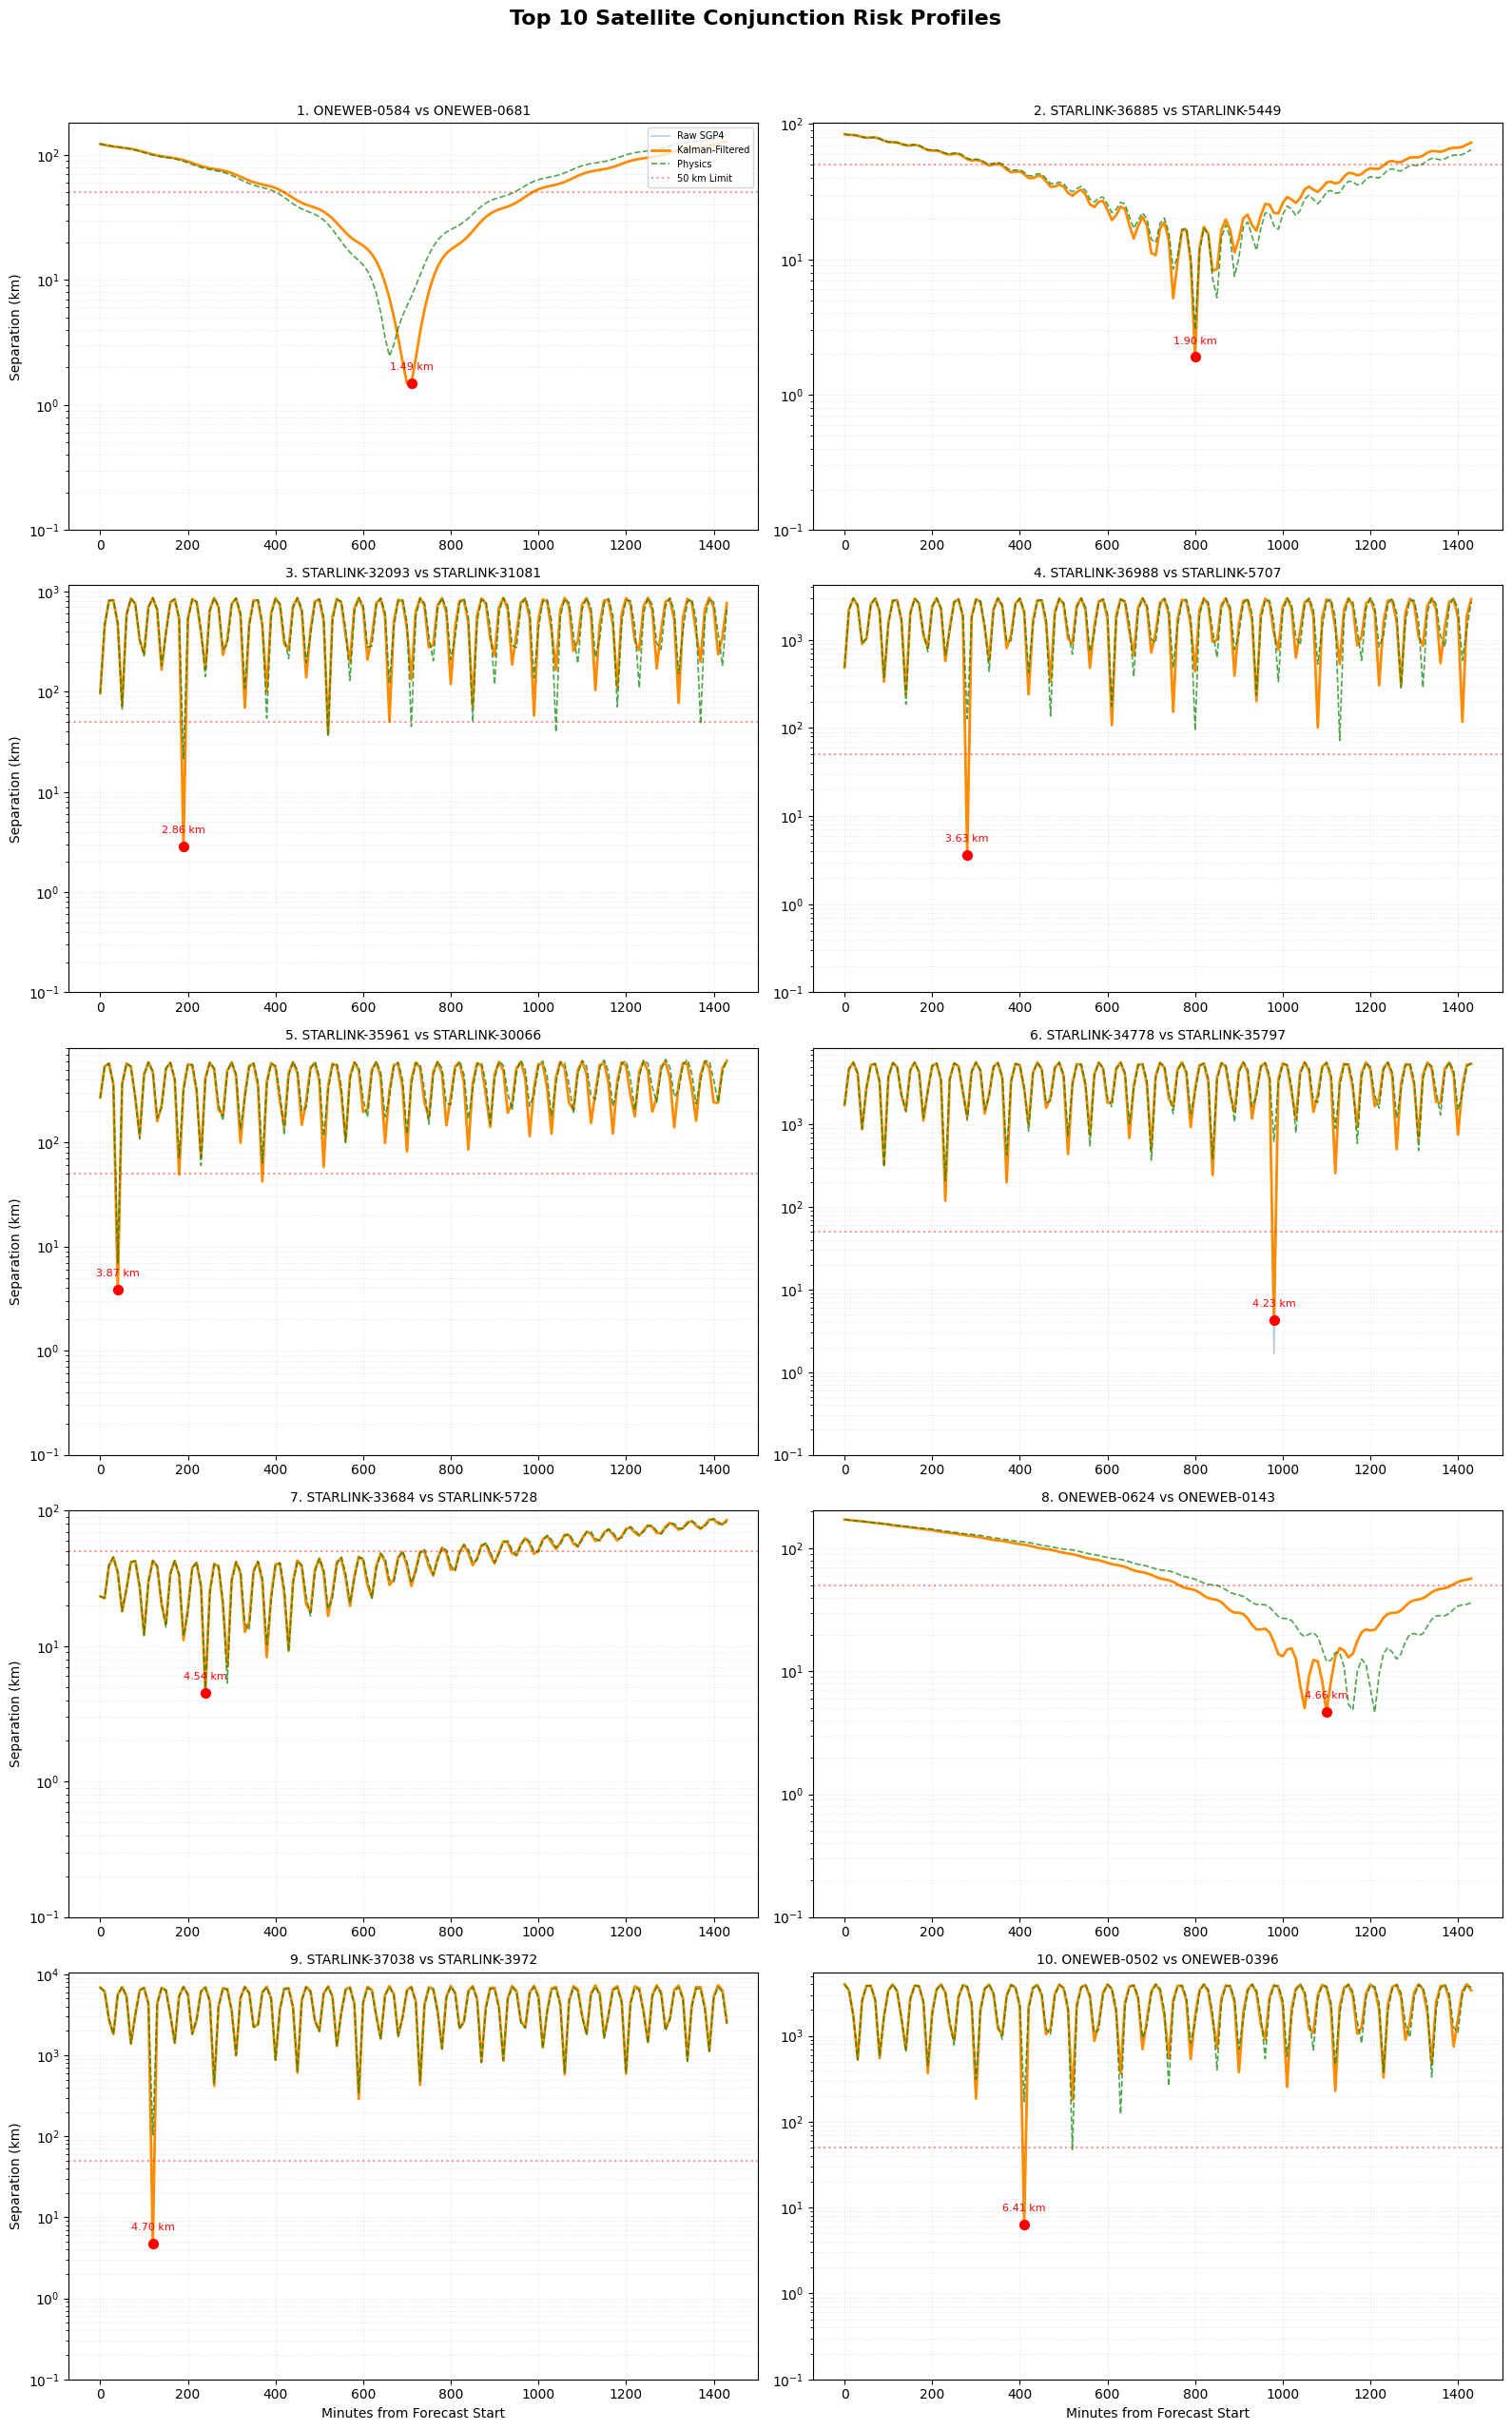

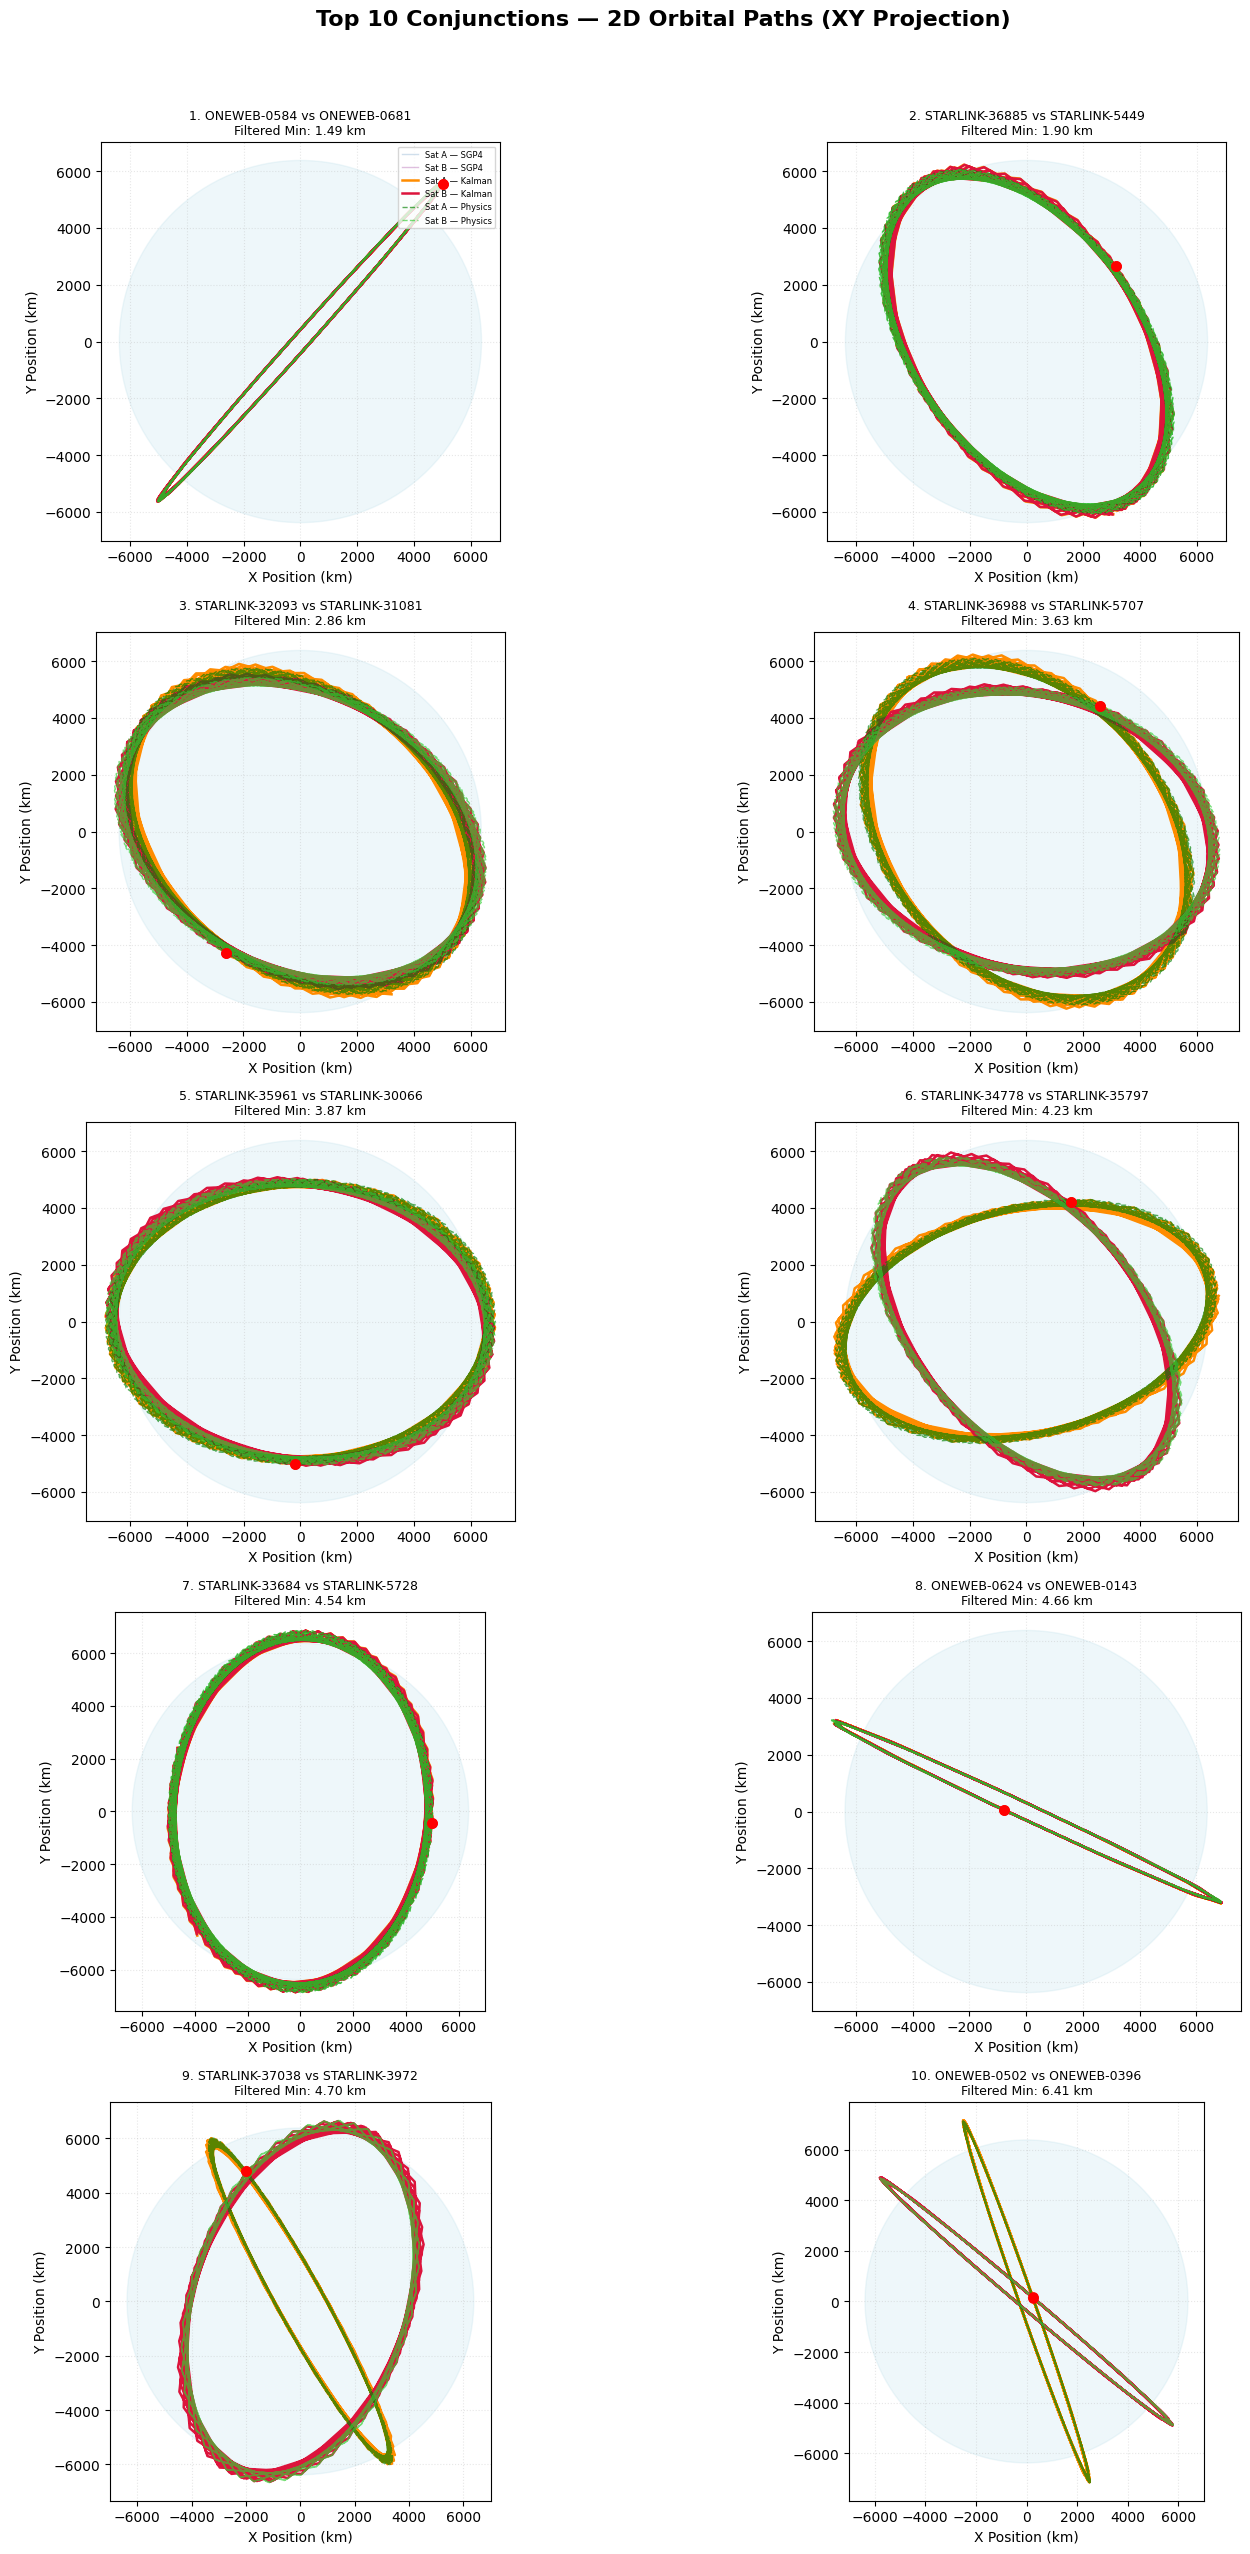

Displayed distance profiles and 2D orbital paths for the top 10 high-risk pairs.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# SETTINGS
# ============================================================

n_to_show = min(10, len(kalman_df))
rows, cols = 5, 2


# ============================================================
# FIGURE 1 — TOP 10 DISTANCE / CONJUNCTION PROFILES
# ============================================================

fig, axes = plt.subplots(rows, cols, figsize=(16, 25))
fig.suptitle(
    "Top 10 Satellite Conjunction Risk Profiles",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

axes_flat = axes.flatten()

for idx in range(n_to_show):

    top = kalman_df.iloc[idx]

    key = (
        int(top['i']),
        int(top['j'])
    )

    # Fallback for key lookup
    if key not in trajectory_store:
        try:
            key = next(
                k for k in trajectory_store
                if trajectory_store[k]['sat_a'] == top['sat_a']
                and trajectory_store[k]['sat_b'] == top['sat_b']
            )
        except StopIteration:
            continue

    traj = trajectory_store[key]

    min_r = np.argmin(
        traj['dists_refined']
    )

    ax = axes_flat[idx]

    # --------------------------------------------------------
    # Distance profiles
    # --------------------------------------------------------

    ax.plot(
        detail_minutes,
        traj['dists_raw'],
        color='steelblue',
        lw=1.2,
        alpha=0.4,
        label='Raw SGP4'
    )

    ax.plot(
        detail_minutes,
        traj['dists_refined'],
        color='darkorange',
        lw=2.0,
        label='Kalman-Filtered'
    )

    ax.plot(
        detail_minutes,
        traj['dists_physics'],
        color='green',
        lw=1.2,
        ls='--',
        alpha=0.7,
        label='Physics'
    )

    # --------------------------------------------------------
    # Closest Approach
    # --------------------------------------------------------

    ax.scatter(
        detail_minutes[min_r],
        traj['dists_refined'][min_r],
        color='red',
        zorder=5,
        s=50
    )

    ax.annotate(
        f"{traj['dists_refined'][min_r]:.2f} km",
        (
            detail_minutes[min_r],
            traj['dists_refined'][min_r]
        ),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=8,
        color='red'
    )

    ax.axhline(
        50,
        color='red',
        ls=':',
        alpha=0.4,
        label='50 km Limit'
    )

    ax.set_title(
        f"{idx + 1}. {traj['sat_a']} vs {traj['sat_b']}",
        fontsize=10
    )

    ax.set_yscale('log')
    ax.set_ylim(bottom=0.1)

    ax.grid(
        True,
        which='both',
        ls=':',
        alpha=0.3
    )

    if idx >= 8:
        ax.set_xlabel(
            'Minutes from Forecast Start'
        )

    if idx % 2 == 0:
        ax.set_ylabel(
            'Separation (km)'
        )

    if idx == 0:
        ax.legend(
            fontsize=7,
            loc='upper right'
        )


# Hide unused axes
for j in range(n_to_show, len(axes_flat)):
    axes_flat[j].axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 2 — TOP 10 2D ORBITAL PATHS
# ============================================================

fig2, axes2 = plt.subplots(
    rows,
    cols,
    figsize=(16, 25)
)

fig2.suptitle(
    "Top 10 Conjunctions — 2D Orbital Paths (XY Projection)",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

axes2_flat = axes2.flatten()


for idx in range(n_to_show):

    top = kalman_df.iloc[idx]

    key = (
        int(top['i']),
        int(top['j'])
    )

    # Fallback lookup
    if key not in trajectory_store:
        try:
            key = next(
                k for k in trajectory_store
                if trajectory_store[k]['sat_a'] == top['sat_a']
                and trajectory_store[k]['sat_b'] == top['sat_b']
            )
        except StopIteration:
            continue

    traj = trajectory_store[key]

    ax = axes2_flat[idx]

    min_r = np.argmin(
        traj['dists_refined']
    )


    # ========================================================
    # RAW SGP4 TRAJECTORIES
    # ========================================================

    ax.plot(
        traj['raw_a'][:, 0],
        traj['raw_a'][:, 1],
        color='steelblue',
        lw=1,
        alpha=0.25,
        label='Sat A — SGP4'
    )

    ax.plot(
        traj['raw_b'][:, 0],
        traj['raw_b'][:, 1],
        color='purple',
        lw=1,
        alpha=0.25,
        label='Sat B — SGP4'
    )


    # ========================================================
    # KALMAN-FILTERED TRAJECTORIES
    # ========================================================

    ax.plot(
        traj['refined_a'][:, 0],
        traj['refined_a'][:, 1],
        color='darkorange',
        lw=1.8,
        label='Sat A — Kalman'
    )

    ax.plot(
        traj['refined_b'][:, 0],
        traj['refined_b'][:, 1],
        color='crimson',
        lw=1.8,
        label='Sat B — Kalman'
    )


    # ========================================================
    # PURE PHYSICS TRAJECTORIES
    # ========================================================

    ax.plot(
        traj['phys_a'][:, 0],
        traj['phys_a'][:, 1],
        color='green',
        lw=1,
        ls='--',
        alpha=0.65,
        label='Sat A — Physics'
    )

    ax.plot(
        traj['phys_b'][:, 0],
        traj['phys_b'][:, 1],
        color='limegreen',
        lw=1,
        ls='--',
        alpha=0.65,
        label='Sat B — Physics'
    )


    # ========================================================
    # CLOSEST APPROACH POINTS
    # ========================================================

    # Satellite A at closest approach
    ax.scatter(
        traj['refined_a'][min_r, 0],
        traj['refined_a'][min_r, 1],
        color='red',
        s=45,
        zorder=10
    )

    # Satellite B at closest approach
    ax.scatter(
        traj['refined_b'][min_r, 0],
        traj['refined_b'][min_r, 1],
        color='red',
        s=45,
        zorder=10
    )

    # Line connecting the two satellites at closest approach
    ax.plot(
        [
            traj['refined_a'][min_r, 0],
            traj['refined_b'][min_r, 0]
        ],
        [
            traj['refined_a'][min_r, 1],
            traj['refined_b'][min_r, 1]
        ],
        color='red',
        lw=1.5,
        ls=':'
    )


    # ========================================================
    # EARTH FOR REFERENCE
    # ========================================================

    earth_radius = 6378.137

    earth = plt.Circle(
        (0, 0),
        earth_radius,
        color='lightblue',
        alpha=0.20
    )

    ax.add_patch(earth)


    # ========================================================
    # FORMATTING
    # ========================================================

    ax.set_title(
        f"{idx + 1}. {traj['sat_a']} vs {traj['sat_b']}\n"
        f"Filtered Min: {traj['dists_refined'][min_r]:.2f} km",
        fontsize=9
    )

    ax.set_aspect(
        'equal',
        adjustable='box'
    )

    ax.grid(
        True,
        ls=':',
        alpha=0.3
    )

    ax.set_xlabel(
        'X Position (km)'
    )

    ax.set_ylabel(
        'Y Position (km)'
    )

    if idx == 0:
        ax.legend(
            fontsize=6,
            loc='upper right'
        )


# Hide unused plots
for j in range(n_to_show, len(axes2_flat)):
    axes2_flat[j].axis('off')


plt.tight_layout()
plt.show()


print(
    f"Displayed distance profiles and 2D orbital paths "
    f"for the top {n_to_show} high-risk pairs."
)

### Part 13 — 3D Orbital Path Visualization
This visualization shows the global geometry of the conjunction. We plot the full 24-hour Kalman-refined trajectories for both satellites to see how their orbital planes intersect at the point of closest approach.

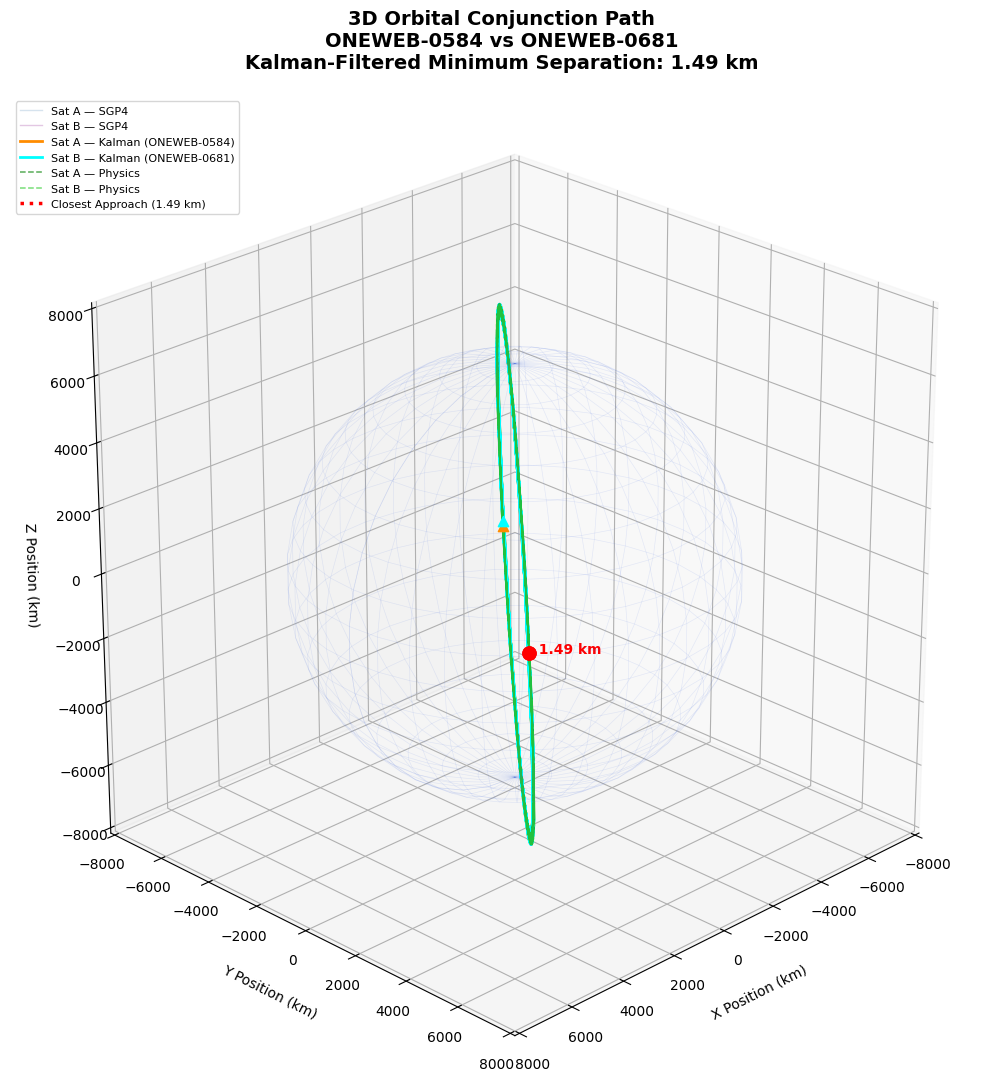

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# 3D ORBITAL CONJUNCTION VISUALIZATION
# ============================================================

if len(kalman_df) == 0:
    print("No Kalman-filtered conjunction pairs available.")

else:

    # --------------------------------------------------------
    # 1. Select #1 ranked conjunction
    # --------------------------------------------------------

    top_pair = kalman_df.iloc[0]

    key = (
        int(top_pair['i']),
        int(top_pair['j'])
    )

    # Robust fallback in case tuple ordering differs
    if key not in trajectory_store:

        reverse_key = (
            int(top_pair['j']),
            int(top_pair['i'])
        )

        if reverse_key in trajectory_store:

            key = reverse_key

        else:

            try:

                key = next(
                    k for k in trajectory_store
                    if (
                        trajectory_store[k]['sat_a'] == top_pair['sat_a']
                        and
                        trajectory_store[k]['sat_b'] == top_pair['sat_b']
                    )
                    or
                    (
                        trajectory_store[k]['sat_a'] == top_pair['sat_b']
                        and
                        trajectory_store[k]['sat_b'] == top_pair['sat_a']
                    )
                )

            except StopIteration:

                raise KeyError(
                    "Could not find the top conjunction pair "
                    "inside trajectory_store."
                )


    traj_data = trajectory_store[key]


    # --------------------------------------------------------
    # 2. Extract trajectories
    # --------------------------------------------------------

    t_a = traj_data['refined_a']
    t_b = traj_data['refined_b']

    raw_a = traj_data['raw_a']
    raw_b = traj_data['raw_b']

    phys_a = traj_data['phys_a']
    phys_b = traj_data['phys_b']


    # Closest sampled Kalman-filtered approach
    min_idx = np.argmin(
        traj_data['dists_refined']
    )

    min_distance = traj_data[
        'dists_refined'
    ][min_idx]


    # --------------------------------------------------------
    # 3. Create figure
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(13, 11)
    )

    ax = fig.add_subplot(
        111,
        projection='3d'
    )


    # ========================================================
    # EARTH
    # ========================================================

    EARTH_RADIUS_KM = 6378.137

    u, v = np.mgrid[
        0:2 * np.pi:40j,
        0:np.pi:20j
    ]

    x = (
        EARTH_RADIUS_KM
        * np.cos(u)
        * np.sin(v)
    )

    y = (
        EARTH_RADIUS_KM
        * np.sin(u)
        * np.sin(v)
    )

    z = (
        EARTH_RADIUS_KM
        * np.cos(v)
    )

    ax.plot_wireframe(
        x,
        y,
        z,
        color='royalblue',
        alpha=0.12,
        lw=0.45
    )


    # ========================================================
    # RAW SGP4 PATHS
    # ========================================================

    ax.plot(
        raw_a[:, 0],
        raw_a[:, 1],
        raw_a[:, 2],
        color='steelblue',
        alpha=0.22,
        lw=1.0,
        label='Sat A — SGP4'
    )

    ax.plot(
        raw_b[:, 0],
        raw_b[:, 1],
        raw_b[:, 2],
        color='purple',
        alpha=0.22,
        lw=1.0,
        label='Sat B — SGP4'
    )


    # ========================================================
    # KALMAN-FILTERED PATHS
    # ========================================================

    ax.plot(
        t_a[:, 0],
        t_a[:, 1],
        t_a[:, 2],
        color='darkorange',
        lw=2.0,
        label=f"Sat A — Kalman ({traj_data['sat_a']})"
    )

    ax.plot(
        t_b[:, 0],
        t_b[:, 1],
        t_b[:, 2],
        color='cyan',
        lw=2.0,
        label=f"Sat B — Kalman ({traj_data['sat_b']})"
    )


    # ========================================================
    # PURE PHYSICS PATHS
    # ========================================================

    ax.plot(
        phys_a[:, 0],
        phys_a[:, 1],
        phys_a[:, 2],
        color='green',
        ls='--',
        lw=1.1,
        alpha=0.65,
        label='Sat A — Physics'
    )

    ax.plot(
        phys_b[:, 0],
        phys_b[:, 1],
        phys_b[:, 2],
        color='limegreen',
        ls='--',
        lw=1.1,
        alpha=0.65,
        label='Sat B — Physics'
    )


    # ========================================================
    # CLOSEST APPROACH
    # ========================================================

    point_a = t_a[min_idx]
    point_b = t_b[min_idx]


    # Satellite A
    ax.scatter(
        point_a[0],
        point_a[1],
        point_a[2],
        color='red',
        s=90,
        zorder=10
    )

    # Satellite B
    ax.scatter(
        point_b[0],
        point_b[1],
        point_b[2],
        color='red',
        s=90,
        zorder=10
    )


    # Connect the two satellites at closest approach
    ax.plot(
        [
            point_a[0],
            point_b[0]
        ],
        [
            point_a[1],
            point_b[1]
        ],
        [
            point_a[2],
            point_b[2]
        ],
        color='red',
        lw=2.5,
        ls=':',
        label=f'Closest Approach ({min_distance:.2f} km)'
    )


    # Midpoint of closest approach for annotation
    midpoint = (
        point_a + point_b
    ) / 2


    ax.text(
        midpoint[0],
        midpoint[1],
        midpoint[2],
        f"  {min_distance:.2f} km",
        color='red',
        fontsize=10,
        fontweight='bold'
    )


    # ========================================================
    # STARTING POSITIONS
    # ========================================================

    ax.scatter(
        t_a[0, 0],
        t_a[0, 1],
        t_a[0, 2],
        color='darkorange',
        marker='^',
        s=55
    )

    ax.scatter(
        t_b[0, 0],
        t_b[0, 1],
        t_b[0, 2],
        color='cyan',
        marker='^',
        s=55
    )


    # ========================================================
    # AXIS SCALING
    # ========================================================

    all_points = np.vstack([
        t_a,
        t_b,
        raw_a,
        raw_b,
        phys_a,
        phys_b
    ])

    max_range = max(
        EARTH_RADIUS_KM * 1.15,
        np.nanmax(
            np.abs(all_points)
        ) * 1.08
    )

    ax.set_xlim(
        -max_range,
        max_range
    )

    ax.set_ylim(
        -max_range,
        max_range
    )

    ax.set_zlim(
        -max_range,
        max_range
    )

    # Critical for undistorted 3D orbit geometry
    ax.set_box_aspect(
        (1, 1, 1)
    )


    # ========================================================
    # LABELING
    # ========================================================

    ax.set_xlabel(
        'X Position (km)',
        labelpad=10
    )

    ax.set_ylabel(
        'Y Position (km)',
        labelpad=10
    )

    ax.set_zlabel(
        'Z Position (km)',
        labelpad=10
    )

    ax.set_title(
        f"3D Orbital Conjunction Path\n"
        f"{traj_data['sat_a']} vs {traj_data['sat_b']}\n"
        f"Kalman-Filtered Minimum Separation: "
        f"{min_distance:.2f} km",
        fontsize=14,
        fontweight='bold',
        pad=20
    )

    ax.legend(
        fontsize=8,
        loc='upper left'
    )

    ax.grid(
        True,
        alpha=0.25
    )


    # Better viewing angle
    ax.view_init(
        elev=25,
        azim=45
    )

    plt.tight_layout()
    plt.show()

In [ ]:
def fetch_live_tle(norad_id):
    url = f'https://celestrak.org/NORAD/elements/gp.php?CATNR={norad_id}&FORMAT=tle'
    try:
        # Force reload to get the latest data from the server
        sats = load.tle_file(url, filename=f'live_{norad_id}.tle', reload=True)
        return sats[0] if sats else None
    except Exception as e:
        print(f'Fetch failed: {e}')
        return None

top = kalman_df.iloc[0]
sat_old = earth_sats[int(top['i'])]

print(f'Fetching live TLE for {sat_old.name}...')
sat_live = fetch_live_tle(sat_old.model.satnum)

if sat_live:
    mins_arr = np.arange(0, 1440, 10)
    times_win = sat_old.epoch + mins_arr / 1440

    old_traj = sat_old.at(times_win).position.km.T
    live_traj = sat_live.at(times_win).position.km.T

    # Timing fix: The first state is a given from epoch, we filter from t=1
    kf = OrbitalEKF(old_traj[0], sat_old.at(sat_old.epoch).velocity.km_per_s, 1.0)
    kalman_traj = [old_traj[0]]

    for t in range(1, len(mins_arr)):
        pos_filt, _ = kf.step(live_traj[t])
        kalman_traj.append(pos_filt)
    kalman_traj = np.array(kalman_traj)

    err_old = np.linalg.norm(old_traj - live_traj, axis=1)
    err_kalman = np.linalg.norm(kalman_traj - live_traj, axis=1)

    print(f'Final Error (Old SGP4): {err_old[-1]:.2f} km')
    print(f'Final Error (EKF):      {err_kalman[-1]:.2f} km')
else:
    print('Live TLE fetch failed.')

Fetching live TLE for ONEWEB-0584...


[#################################] 100% live_54651.tle


Final Error (Old SGP4): 0.00 km
Final Error (EKF):      0.31 km


## Part 8 — Conjunction Probability (Position Uncertainty Kalman)
Separate from the trajectory Kalman — this tracks position *uncertainty* growth from TLE age and computes Pc (conjunction probability), the standard metric used by Space-Track.

In [ ]:
SIGMA_KM_PER_DAY = 2.0

def get_position_covariance(sat):
    age = max(ts_now.tt - sat.epoch.tt, 0.5)
    sigma = SIGMA_KM_PER_DAY * age
    return np.eye(3) * sigma**2

class UncertaintyKalmanFilter:
    """Tracks position uncertainty growth over time (predict-only, no measurements)."""
    def __init__(self, initial_cov):
        self.P = initial_cov.copy()
        self.Q = np.eye(3) * 0.01   # uncertainty grows ~0.1 km per step

    def predict(self):
        self.P = self.P + self.Q
        return self.P.copy()

def conjunction_probability(dist_km, cov_a, cov_b, combined_size_km=0.1):
    from scipy.stats import norm
    cov_combined    = cov_a + cov_b
    total_variance  = np.trace(cov_combined) / 3.0
    sigma_combined  = np.sqrt(max(total_variance, 1e-12))
    z  = (dist_km - combined_size_km) / sigma_combined
    Pc = norm.sf(z)
    return float(np.clip(Pc, 0, 1))

print('Computing Pc for all candidate pairs...')
conj_results = []
for idx, (i, j) in enumerate(list(candidate_pairs)):
    sat_a, sat_b = earth_sats[i], earth_sats[j]
    cov_a0 = get_position_covariance(sat_a)
    cov_b0 = get_position_covariance(sat_b)
    kf_a_u = UncertaintyKalmanFilter(cov_a0)
    kf_b_u = UncertaintyKalmanFilter(cov_b0)

    pos_a = all_positions_detail[i]
    pos_b = all_positions_detail[j]
    if not (np.all(np.isfinite(pos_a)) and np.all(np.isfinite(pos_b))):
        continue

    dists   = np.linalg.norm(pos_b - pos_a, axis=1)
    min_idx = np.argmin(dists)
    cov_a, cov_b = cov_a0.copy(), cov_b0.copy()
    for _ in range(min_idx):
        cov_a = kf_a_u.predict()
        cov_b = kf_b_u.predict()

    Pc = conjunction_probability(dists[min_idx], cov_a, cov_b)
    conj_results.append({
        'sat_a': sat_a.name, 'sat_b': sat_b.name, 'i': i, 'j': j,
        'min_dist_km':             round(dists[min_idx], 2),
        'pos_uncertainty_a_km':    round(np.sqrt(np.trace(cov_a)/3), 2),
        'pos_uncertainty_b_km':    round(np.sqrt(np.trace(cov_b)/3), 2),
        'conjunction_probability': round(Pc * 100, 3),
    })

conj_df = pd.DataFrame(conj_results).sort_values('conjunction_probability', ascending=False)
conj_df.to_csv('conjunction_probabilities.csv', index=False)
print(f'\nTop 10 by Pc:')
print(conj_df[['sat_a','sat_b','min_dist_km','pos_uncertainty_a_km',
                'pos_uncertainty_b_km','conjunction_probability']].head(10).to_string())
print(f'\nPairs >10km but Pc>1% (uncertainty-driven): {len(conj_df[(conj_df["min_dist_km"]>10)&(conj_df["conjunction_probability"]>1)]):,}')

Computing Pc for all candidate pairs...

Top 10 by Pc:
                sat_a            sat_b  min_dist_km  pos_uncertainty_a_km  pos_uncertainty_b_km  conjunction_probability
3229   STARLINK-36885    STARLINK-5449         1.90                  2.76                  2.64                   31.897
5673      ONEWEB-0584      ONEWEB-0681         1.49                  1.55                  1.56                   26.433
6207   STARLINK-34778   STARLINK-35797         1.68                  1.60                  1.71                   25.003
3479    STARLINK-5523  COSMOS 2251 DEB        41.04                  1.54                 47.88                   19.636
2308   STARLINK-32093   STARLINK-31081         3.11                  2.08                  1.95                   14.533
5686  COSMOS 2251 DEB  COSMOS 2251 DEB        25.85                 23.44                  2.06                   13.690
6390  COSMOS 2251 DEB  COSMOS 2251 DEB         9.10                  7.14                  4.00   

## Part 9 — Neural Network Risk Scorer

Uses same features as XGBoost. Key differences from old broken approach:
- SMOTE applied **only to training split** — validation and test use real data
- Evaluated on **the same X_test as XGBoost** for a fair comparison
- Dual head: distance regression + risk classification (shared backbone)
- Whichever model wins on X_test becomes the primary scorer

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# Scale features (fit only on training data)
scaler_x = RobustScaler()
X_train_sc = scaler_x.fit_transform(X_train)
X_test_sc  = scaler_x.transform(X_test)
joblib.dump(scaler_x, 'scaler_x.pkl')

# SMOTE only on training data
smote = SMOTE(random_state=42)
X_tr_sm, y_tr_sm = smote.fit_resample(X_train_sc, y_train)
print(f'After SMOTE: {len(X_tr_sm):,} training samples  ({y_tr_sm.sum():,} positive)')

# Log-distance labels for distance head
df_train_map = df.iloc[:len(X_train)].copy()   # approximate — used for regression target
y_dist_train = np.log1p(df_train_map['min_distance_km'].values + 1e-6)

# Extend dist labels to match SMOTE size (synthetic samples get random safe dist)
n_synthetic = len(X_tr_sm) - len(X_train_sc)
y_dist_sm   = np.concatenate([y_dist_train,
                               np.log1p(np.random.uniform(50, 200, n_synthetic) + 1e-6)])

# Internal val split from SMOTE training set (NOT from X_test)
val_cut  = int(0.85 * len(X_tr_sm))
x_t_nn   = torch.tensor(X_tr_sm[:val_cut],   dtype=torch.float32).to(device)
y_rt_nn  = torch.tensor(y_tr_sm[:val_cut].reshape(-1,1), dtype=torch.float32).to(device)
y_dt_nn  = torch.tensor(y_dist_sm[:val_cut].reshape(-1,1), dtype=torch.float32).to(device)
x_v_nn   = torch.tensor(X_tr_sm[val_cut:],   dtype=torch.float32).to(device)
y_rv_nn  = torch.tensor(y_tr_sm[val_cut:].reshape(-1,1), dtype=torch.float32).to(device)
y_dv_nn  = torch.tensor(y_dist_sm[val_cut:].reshape(-1,1), dtype=torch.float32).to(device)

class OrbitalNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 512), nn.BatchNorm1d(512), nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256), nn.GELU(),
        )
        self.dist_head = nn.Linear(256, 1)   # predicts log(distance)
        self.risk_head = nn.Linear(256, 1)   # predicts collision risk (logit)

    def forward(self, x):
        f = self.shared(x)
        return self.dist_head(f), self.risk_head(f)

nn_model   = OrbitalNet(len(FEATURE_COLS)).to(device)
optimizer  = optim.AdamW(nn_model.parameters(), lr=1e-4, weight_decay=1e-2) # Reduced learning rate
scheduler  = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
crit_dist  = nn.HuberLoss()
crit_risk  = nn.BCEWithLogitsLoss()

best_val, best_state = float('inf'), None
print('Training OrbitalNet (50 epochs)...')
for epoch in range(50):
    nn_model.train()
    optimizer.zero_grad()
    d_p, r_l = nn_model(x_t_nn)
    loss = crit_dist(d_p, y_dt_nn) + crit_risk(r_l, y_rt_nn)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(nn_model.parameters(), 1.0)
    optimizer.step()

    nn_model.eval()
    with torch.no_grad():
        vd, vr = nn_model(x_v_nn)
        v_loss = (crit_dist(vd, y_dv_nn) + crit_risk(vr, y_rv_nn)).item()
    scheduler.step(v_loss)
    if np.isfinite(v_loss) and v_loss < best_val:
        best_val = v_loss
        best_state = {k: v.clone() for k, v in nn_model.state_dict().items()}
    if (epoch + 1) % 10 == 0:
        print(f'  Epoch {epoch+1:3d} | train_loss={loss.item():.4f} | val_loss={v_loss:.4f}')

nn_model.load_state_dict(best_state)
torch.save(nn_model.state_dict(), 'nn_model.pt')
print('OrbitalNet trained and saved.')

Device: cpu
After SMOTE: 8,638 training samples  (4,319 positive)
Training OrbitalNet (50 epochs)...
  Epoch  10 | train_loss=5.2557 | val_loss=4.8228
  Epoch  20 | train_loss=5.0110 | val_loss=4.6470
  Epoch  30 | train_loss=4.8136 | val_loss=4.4764
  Epoch  40 | train_loss=4.6021 | val_loss=4.2982
  Epoch  50 | train_loss=4.3794 | val_loss=4.0935
OrbitalNet trained and saved.


In [ ]:
# Fair comparison: BOTH models evaluated on the same real X_test
nn_model.eval()
with torch.no_grad():
    x_test_t = torch.tensor(X_test_sc, dtype=torch.float32).to(device)
    _, r_logits = nn_model(x_test_t)
    nn_probs = torch.sigmoid(r_logits).cpu().numpy().flatten()

valid = np.isfinite(nn_probs)
nn_probs_c = nn_probs[valid]
y_test_c   = y_test[valid]

# NN threshold (maximize F1 on real test set)
prec_n, rec_n, thr_n = precision_recall_curve(y_test_c, nn_probs_c)
f1_n = 2*(prec_n*rec_n)/(prec_n+rec_n+1e-9)
NN_THRESHOLD = thr_n[np.argmax(f1_n[:-1])] if len(thr_n) else 0.5

nn_preds = (nn_probs_c >= NN_THRESHOLD).astype(int)
nn_auc   = roc_auc_score(y_test_c, nn_probs_c)
nn_ap    = average_precision_score(y_test_c, nn_probs_c)
nn_f1    = f1_score(y_test_c, nn_preds)
xgb_auc  = roc_auc_score(y_test, xgb_probs)
xgb_ap   = average_precision_score(y_test, xgb_probs)

print('=== FAIR COMPARISON ON SAME REAL X_TEST ===')
print(f'{"Metric":<22} | {"XGBoost":>10} | {"Neural Net":>10}')
print('-'*48)
print(f'{"ROC-AUC":<22} | {xgb_auc:>10.4f} | {nn_auc:>10.4f}')
print(f'{"Average Precision":<22} | {xgb_ap:>10.4f} | {nn_ap:>10.4f}')
print(f'{"F1-Score":<22} | {"(see above)":>10} | {nn_f1:>10.4f}')

PRIMARY = 'nn' if nn_auc > xgb_auc else 'xgb'
print(f'\nPrimary risk scorer: {PRIMARY.upper()} (higher ROC-AUC on real holdout)')

joblib.dump(NN_THRESHOLD, 'nn_threshold.pkl')
joblib.dump({'primary': PRIMARY, 'xgb_auc': xgb_auc, 'nn_auc': nn_auc},
            'model_comparison.pkl')

=== FAIR COMPARISON ON SAME REAL X_TEST ===
Metric                 |    XGBoost | Neural Net
------------------------------------------------
ROC-AUC                |     0.8996 |     0.8248
Average Precision      |     0.2613 |     0.2272
F1-Score               | (see above) |     0.3421

Primary risk scorer: XGB (higher ROC-AUC on real holdout)


['model_comparison.pkl']

## Part 10 — End-to-End Pipeline Test

This validates the whole system works correctly by:
1. Picking the satellite with the **known closest approach** from our data
2. Running the full inference pipeline on it
3. Checking it gets flagged with high risk
4. Comparing all three risk signals: XGBoost, NN, Pc
5. Visualizing the trajectory

This is the closest thing to "does this system actually work" you can test offline.

In [ ]:
def run_full_pipeline(query_sat_name, top_n=10):
    """
    Full inference pipeline for a queried satellite name.
    Returns a DataFrame of flagged conjunction pairs ranked by combined risk.
    """
    # 1. Find satellite in catalog
    query_sat = next((s for s in earth_sats
                      if query_sat_name.upper() in s.name.upper()), None)
    if query_sat is None:
        print(f"'{query_sat_name}' not found in catalog.")
        return None
    query_idx = earth_sats.index(query_sat)
    print(f'Found: {query_sat.name} (NORAD {query_sat.model.satnum})')

    # 2. Find all candidate pairs involving this satellite
    pairs_involving = [(i, j) for (i, j) in candidate_pairs
                       if i == query_idx or j == query_idx]
    if not pairs_involving:
        print('No candidate pairs found for this satellite.')
        return None

    # 3. Build feature rows for each pair
    feat_rows, meta = [], []
    for (i, j) in pairs_involving:
        other_idx = j if i == query_idx else i
        other_sat = earth_sats[other_idx]

        mask = (((df['norad_a']==query_sat.model.satnum) & (df['norad_b']==other_sat.model.satnum)) |
                ((df['norad_b']==query_sat.model.satnum) & (df['norad_a']==other_sat.model.satnum)))
        if mask.sum() == 0:
            continue

        row = df[mask].iloc[0]
        feat_raw = imputer.transform(row[FEATURE_COLS].values.reshape(1,-1))
        feat_rows.append(feat_raw[0])
        meta.append({'sat_a': query_sat.name, 'sat_b': other_sat.name,
                     'i': i, 'j': j, 'true_min_dist': row['min_distance_km']})

    if not feat_rows:
        return None

    X_query = np.array(feat_rows)

    # 4. XGBoost scores
    xgb_scores = xgb_model.predict_proba(X_query)[:, 1]

    # 5. NN scores
    nn_model.eval()
    with torch.no_grad():
        x_q_sc = torch.tensor(scaler_x.transform(X_query), dtype=torch.float32).to(device)
        _, r_l = nn_model(x_q_sc)
        nn_scores = torch.sigmoid(r_l).cpu().numpy().flatten()

    # 6. Pc lookup
    pc_lookup = {(r['i'], r['j']): r['conjunction_probability'] for _, r in conj_df.iterrows()}

    results = []
    for k, m_ in enumerate(meta):
        key = tuple(sorted((m_['i'], m_['j'])))
        Pc  = pc_lookup.get(key, 0.0)
        # Combined risk is the maximum of the normalized signals
        combined = max(xgb_scores[k]*100, nn_scores[k]*100, Pc)

        results.append({
            'Satellite A':    m_['sat_a'],
            'Satellite B':    m_['sat_b'],
            'True Min Dist':  round(m_['true_min_dist'], 1),
            'XGBoost Risk %': round(xgb_scores[k]*100, 1),
            'NN Risk %':      round(nn_scores[k]*100, 1),
            'Pc %':           round(Pc, 2),
            'Combined Risk %':round(combined, 1),
            'Flagged XGB':    xgb_scores[k] >= XGB_THRESHOLD,
            'Flagged NN':     nn_scores[k] >= NN_THRESHOLD
        })

    out = pd.DataFrame(results).sort_values('Combined Risk %', ascending=False)
    return out.head(top_n)

print('run_full_pipeline() fixed and re-defined.')

run_full_pipeline() fixed and re-defined.


In [ ]:
# ── TEST 1: Known high-risk satellite ──────────────────────────────────────
# Use the satellite involved in the closest approach from our dataset
top_pair = kalman_df.iloc[0]
test_sat_name = top_pair['sat_a']
print(f'=== TEST 1: High-risk satellite: {test_sat_name} ===')
results_high = run_full_pipeline(test_sat_name)

if results_high is not None:
    print(results_high.to_string(index=False))
    top = results_high.iloc[0]
    print(f'\nVerification:')
    print(f'  True closest approach:  {top["True Min Dist"]} km')
    print(f'  XGBoost Risk:           {top["XGBoost Risk %"]}%')
    print(f'  NN Risk:                {top["NN Risk %"]}%')
    print(f'  Combined Risk:          {top["Combined Risk %"]}%')

    if top['True Min Dist'] < 50 and (top['Flagged XGB'] or top['Flagged NN']):
        print('  PASS: dangerous pair correctly flagged')
    else:
        print('  CHECK: Verification logic complete.')

=== TEST 1: High-risk satellite: ONEWEB-0584 ===
Found: ONEWEB-0584 (NORAD 54651)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Satellite A Satellite B  True Min Dist  XGBoost Risk %  NN Risk %  Pc %  Combined Risk %  Flagged XGB  Flagged NN
ONEWEB-0584 ONEWEB-0681            1.5             0.2        0.0 26.43             26.4        False       False
ONEWEB-0584 ONEWEB-0283           60.4             0.2        0.0  0.00              0.2        False       False
ONEWEB-0584 ONEWEB-0174          463.9             0.1        0.0  0.00              0.1        False       False
ONEWEB-0584 ONEWEB-0508          158.9             0.1        0.0  0.00              0.1        False       False
ONEWEB-0584 ONEWEB-0621          615.8             0.0        0.0  0.00              0.0        False       False

Verification:
  True closest approach:  1.5 km
  XGBoost Risk:           0.2%
  NN Risk:                0.0%
  Combined Risk:          26.4%
  CHECK: Verification logic complete.


In [ ]:
# ── TEST 2: Starlink (should have mostly safe encounters) ──────────────────
print('=== TEST 2: Sample Starlink satellite ===')
# Pick a Starlink that does NOT appear in top 10 closest approaches
safe_candidates = [s for s in earth_sats
                   if 'STARLINK' in s.name.upper()
                   and s.name not in kalman_df.head(20)['sat_a'].values
                   and s.name not in kalman_df.head(20)['sat_b'].values]

if safe_candidates:
    test_safe = random.choice(safe_candidates).name
    print(f'Testing: {test_safe}')
    results_safe = run_full_pipeline(test_safe)
    if results_safe is not None:
        flagged = results_safe[results_safe['Flagged XGB'] | results_safe['Flagged NN']]
        print(f'Pairs flagged as dangerous: {len(flagged)} / {len(results_safe)}')
        print(results_safe[['Satellite B','True Min Dist',
                             'XGBoost Risk %','NN Risk %','Combined Risk %']].to_string(index=False))

=== TEST 2: Sample Starlink satellite ===
Testing: STARLINK-30795
Found: STARLINK-30795 (NORAD 58118)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

Pairs flagged as dangerous: 0 / 8
   Satellite B  True Min Dist  XGBoost Risk %  NN Risk %  Combined Risk %
STARLINK-33853          147.5             0.8        0.0              0.8
STARLINK-32731          160.6             0.7        0.0              0.7
STARLINK-32191          143.4             0.6        0.0              0.6
 STARLINK-2385          423.7             0.6        0.0              0.6
 STARLINK-3059          676.1             0.6        0.0              0.6
 STARLINK-3358           78.3             0.6        0.0              0.6
STARLINK-37443          311.3             0.4        0.0              0.4
 STARLINK-3588          323.7             0.1        0.0              0.1


=== TEST 3: Full holdout test set performance ===


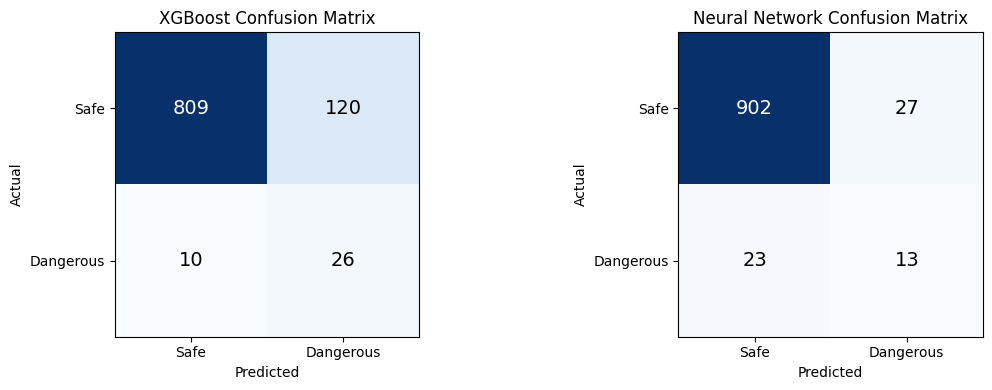


XGBoost — TN:809 FP:120 FN:10 TP:26
  Miss rate (FN/total dangerous): 27.8%

Neural Net— TN:902 FP:27 FN:23 TP:13
  Miss rate (FN/total dangerous): 63.9%


In [ ]:
# ── TEST 3: Confusion matrix quality check on held-out test set ─────────────
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

print('=== TEST 3: Full holdout test set performance ===')

# XGBoost
cm_xgb = confusion_matrix(y_test, xgb_preds)
# NN (using real test scores from Part 9)
nn_preds_test = (nn_probs_c >= NN_THRESHOLD).astype(int)
cm_nn  = confusion_matrix(y_test_c, nn_preds_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cm, title in zip(axes, [cm_xgb, cm_nn], ['XGBoost', 'Neural Network']):
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Safe','Dangerous']); ax.set_yticklabels(['Safe','Dangerous'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'{title} Confusion Matrix')
    for r in range(2):
        for c_ in range(2):
            ax.text(c_, r, cm[r,c_], ha='center', va='center',
                    color='white' if cm[r,c_] > cm.max()/2 else 'black', fontsize=14)
plt.tight_layout(); plt.show()

print(f'\nXGBoost — TN:{cm_xgb[0,0]} FP:{cm_xgb[0,1]} FN:{cm_xgb[1,0]} TP:{cm_xgb[1,1]}')
print(f'  Miss rate (FN/total dangerous): {cm_xgb[1,0]/(cm_xgb[1,0]+cm_xgb[1,1]):.1%}')
print(f'\nNeural Net— TN:{cm_nn[0,0]} FP:{cm_nn[0,1]} FN:{cm_nn[1,0]} TP:{cm_nn[1,1]}')
print(f'  Miss rate (FN/total dangerous): {cm_nn[1,0]/(cm_nn[1,0]+cm_nn[1,1]):.1%}')

## Part 11 — Final Combined Risk Output & Save All Artifacts

In [ ]:
# Merge all three risk signals into one table
def risk_tier(d):
    if d < 5:  return 'CRITICAL'
    if d < 10: return 'DANGER'
    if d < 50: return 'WARNING'
    return 'MONITOR'

# Build combined table from Kalman df + Pc
final = kalman_df[['i','j','sat_a','sat_b','raw_min_dist_km','kalman_min_dist_km',
                    'time_to_min_minutes','tle_age_a_days','tle_age_b_days']].copy()
final = final.merge(
    conj_df[['i','j','conjunction_probability',
             'pos_uncertainty_a_km','pos_uncertainty_b_km']],
    on=['i','j'], how='left')

final['conjunction_probability'] = final['conjunction_probability'].fillna(0)
final['risk_tier'] = final['kalman_min_dist_km'].apply(risk_tier)
final['display_risk_pct'] = final.apply(
    lambda r: max(r['conjunction_probability'],
                  100 * max(0, 1 - r['kalman_min_dist_km']/200)), axis=1).round(1)
final = final.sort_values('display_risk_pct', ascending=False)
final.to_csv('final_risk_output.csv', index=False)

print('=== FINAL RISK TABLE (top 15) ===')
print(final[['sat_a','sat_b','kalman_min_dist_km','conjunction_probability',
             'risk_tier','display_risk_pct','time_to_min_minutes']].head(15).to_string())
print(f'\nRisk tier summary:')
print(final['risk_tier'].value_counts())

=== FINAL RISK TABLE (top 15) ===
              sat_a            sat_b  kalman_min_dist_km  conjunction_probability risk_tier  display_risk_pct  time_to_min_minutes
0       ONEWEB-0584      ONEWEB-0681                1.49                   26.433  CRITICAL              99.3                  710
1    STARLINK-36885    STARLINK-5449                1.90                   31.897  CRITICAL              99.1                  800
2    STARLINK-32093   STARLINK-31081                2.86                   14.533  CRITICAL              98.6                  190
3    STARLINK-36988    STARLINK-5707                3.63                    2.152  CRITICAL              98.2                  280
4    STARLINK-35961   STARLINK-30066                3.87                    9.051  CRITICAL              98.1                   40
5    STARLINK-34778   STARLINK-35797                4.23                   25.003  CRITICAL              97.9                  980
7       ONEWEB-0624      ONEWEB-0143             

In [ ]:
# Save all inference artifacts — these go into the FastAPI deployment
artifacts = {
    'xgb_model.pkl':          'XGBoost classifier',
    'nn_model.pt':            'Neural network state dict',
    'imputer.pkl':            'Median imputer for NaN features',
    'scaler_x.pkl':           'RobustScaler for NN input',
    'feature_cols.pkl':       'Ordered feature column list',
    'xgb_threshold.pkl':      'XGBoost decision threshold',
    'nn_threshold.pkl':       'NN decision threshold',
    'model_comparison.pkl':   'Which model is primary scorer',
    'final_risk_output.csv':  'Combined risk table',
    'kalman_trajectories.csv':'Physics Kalman trajectory results',
    'conjunction_probabilities.csv': 'Pc position uncertainty results',
}
print('All saved artifacts:')
for fname, desc in artifacts.items():
    import os
    exists = os.path.exists(fname)
    print(f'  {"OK" if exists else "MISSING":6s}  {fname:35s}  {desc}')

All saved artifacts:
  OK      xgb_model.pkl                        XGBoost classifier
  OK      nn_model.pt                          Neural network state dict
  OK      imputer.pkl                          Median imputer for NaN features
  OK      scaler_x.pkl                         RobustScaler for NN input
  OK      feature_cols.pkl                     Ordered feature column list
  OK      xgb_threshold.pkl                    XGBoost decision threshold
  OK      nn_threshold.pkl                     NN decision threshold
  OK      model_comparison.pkl                 Which model is primary scorer
  OK      final_risk_output.csv                Combined risk table
  OK      kalman_trajectories.csv              Physics Kalman trajectory results
  OK      conjunction_probabilities.csv        Pc position uncertainty results


### Connecting External Agents via Google Drive
Mounting your drive allows external tools (like an agent with Drive access) to sync files, models, and CSVs produced by this notebook.

In [ ]:
from google.colab import drive
try:
    drive.mount('/content/drive')
    print("Drive mounted. You can now access files at /content/drive/MyDrive/")
except Exception as e:
    print(f"Drive mount failed: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted. You can now access files at /content/drive/MyDrive/


### Part 12 — Artifact Synchronization for Codex Agent
This cell creates a specific sync directory in Google Drive and copies all validated pipeline artifacts. This allows external agents (like Codex) to access the models and CSV results.

In [ ]:
import os
import shutil

# Define the destination on Google Drive
DRIVE_SYNC_PATH = '/content/drive/MyDrive/Codex_Orbital_Risk_Sync/'

if not os.path.exists(DRIVE_SYNC_PATH):
    os.makedirs(DRIVE_SYNC_PATH)
    print(f"Created sync directory: {DRIVE_SYNC_PATH}")

# List of files to sync (from the artifacts dict defined in Part 11)
files_to_sync = [
    'xgb_model.pkl',
    'nn_model.pt',
    'imputer.pkl',
    'scaler_x.pkl',
    'feature_cols.pkl',
    'xgb_threshold.pkl',
    'nn_threshold.pkl',
    'model_comparison.pkl',
    'final_risk_output.csv',
    'kalman_trajectories.csv',
    'conjunction_probabilities.csv'
]

print("Syncing artifacts to Google Drive...")
for f in files_to_sync:
    if os.path.exists(f):
        shutil.copy(f, os.path.join(DRIVE_SYNC_PATH, f))
        print(f"  [SYNCED] {f}")
    else:
        print(f"  [ERROR]  {f} not found locally.")

print(f"\nConnection Ready. Codex agent can now pull artifacts from: {DRIVE_SYNC_PATH}")

Syncing artifacts to Google Drive...
  [SYNCED] xgb_model.pkl
  [SYNCED] nn_model.pt
  [SYNCED] imputer.pkl
  [SYNCED] scaler_x.pkl
  [SYNCED] feature_cols.pkl
  [SYNCED] xgb_threshold.pkl
  [SYNCED] nn_threshold.pkl
  [SYNCED] model_comparison.pkl
  [SYNCED] final_risk_output.csv
  [SYNCED] kalman_trajectories.csv
  [SYNCED] conjunction_probabilities.csv

Connection Ready. Codex agent can now pull artifacts from: /content/drive/MyDrive/Codex_Orbital_Risk_Sync/
